# Glassdoor İş İlanları Üzerinden Maaş Tahminleme ve Optimizasyon

Bu çalışma, Glassdoor üzerinden alınan veri bilimi ve teknoloji odaklı iş ilanlarını analiz ederek, şirket özelliklerine (rating, yaş, sektör vb.) göre **yıllık ortalama maaş tahmini** yapmayı amaçlamaktadır.

### Projenin Temel Hedefleri:
1. **Veri Temizleme:** Kirli metin verilerinden (maaş aralıkları, şirket yaşları) anlamlı sayısal özellikler türetmek.
2. **İlişkisel Analiz:** Kategorik değişkenler arasındaki güçlü korelasyonları (Örn: Lokasyon-Sektör ilişkisi) kullanarak eksik verileri doldurmak.
3. **Özel Kayıp Fonksiyonları (Custom Loss):** Standart metriklerin (MSE, MAE) yetersiz kaldığı durumlarda, iş hedeflerine (İK bütçe planlaması vb.) uygun özel maliyet fonksiyonları tasarlamak.

In [51]:
import pandas as pd 
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from math import pi
import seaborn as sns
import os
%matplotlib inline 
import warnings
warnings.filterwarnings("ignore")


In [52]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

Veriyi çekiyoruz.

In [53]:
import kagglehub
path = kagglehub.dataset_download("thedevastator/jobs-dataset-from-glassdoor")
print("Path to dataset files:", path)

In [54]:
csv_file_name = "glassdoor_jobs.csv"
full_path = os.path.join(path, csv_file_name)

VERİYE İLK BAKIŞ

In [55]:
df = pd.read_csv(full_path)
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


VERİ TİPLERİNE BAKIYORUZ BİLGİ EDİNİYORUZ DEĞİŞKENLER İLE İLGİLİ

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         956 non-null    int64  
 1   Job Title          956 non-null    str    
 2   Salary Estimate    956 non-null    str    
 3   Job Description    956 non-null    str    
 4   Rating             956 non-null    float64
 5   Company Name       956 non-null    str    
 6   Location           956 non-null    str    
 7   Headquarters       956 non-null    str    
 8   Size               956 non-null    str    
 9   Founded            956 non-null    int64  
 10  Type of ownership  956 non-null    str    
 11  Industry           956 non-null    str    
 12  Sector             956 non-null    str    
 13  Revenue            956 non-null    str    
 14  Competitors        956 non-null    str    
dtypes: float64(1), int64(2), str(12)
memory usage: 112.2 KB


In [57]:
display(df.describe(include=['object', 'category']).T)
display(df.describe().T)

,count,unique,top,freq
Job Title,956,328,Data Scientist,178
Salary Estimate,956,417,-1,214
Job Description,956,596,We are looking for enthusiastic and talented i...,4
Company Name,956,448,Takeda Pharmaceuticals\n3.7,14
Location,956,237,"New York, NY",78
Headquarters,956,235,"New York, NY",75
Size,956,9,1001 to 5000 employees,177
Type of ownership,956,13,Company - Private,532
Industry,956,63,Biotech & Pharmaceuticals,148
Sector,956,25,Information Technology,239


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,956.0,477.500000,276.117729,0.0,238.75,477.5,716.25,955.0
Rating,956.0,3.601255,1.067619,-1.0,3.30,3.8,4.20,5.0
Founded,956.0,1774.605649,598.942517,-1.0,1937.00,1992.0,2008.00,2019.0


In [58]:
df.isnull().sum()

Unnamed: 0           0
Job Title            0
Salary Estimate      0
Job Description      0
Rating               0
Company Name         0
Location             0
Headquarters         0
Size                 0
Founded              0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
Competitors          0
dtype: int64

NaN değer yok gibi görünmekle birlikte bazı string değişkenlerde ve bazı sayısal değişkenlerde bu NaN değerlerler yazı ile ya da değer ile doldurulmuş bunlardan bazıları ise -1 yazanlar

In [59]:
df.replace(-1, np.nan, inplace=True);
df.replace('-1', np.nan, inplace=True);

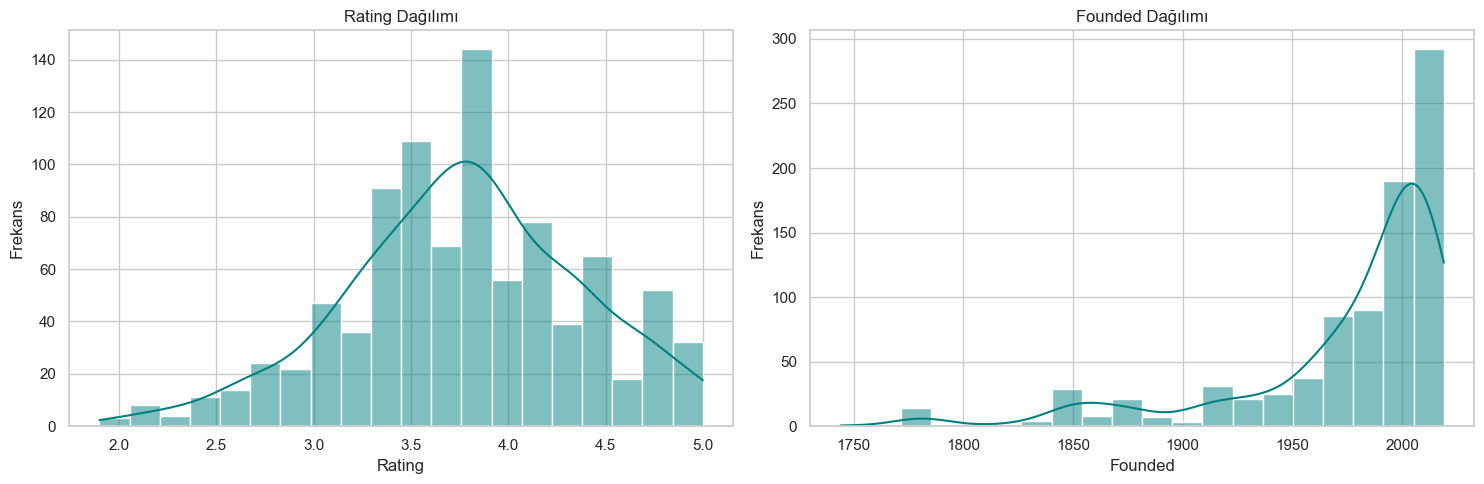

In [60]:
num_cols = ['Rating', 'Founded']

plt.figure(figsize=(15, 5))

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 2, i)
    sns.histplot(df[col].dropna(), kde=True, color='teal', bins=20)
    plt.title(f'{col} Dağılımı')
    plt.xlabel(col)
    plt.ylabel('Frekans')

plt.tight_layout()
plt.show()

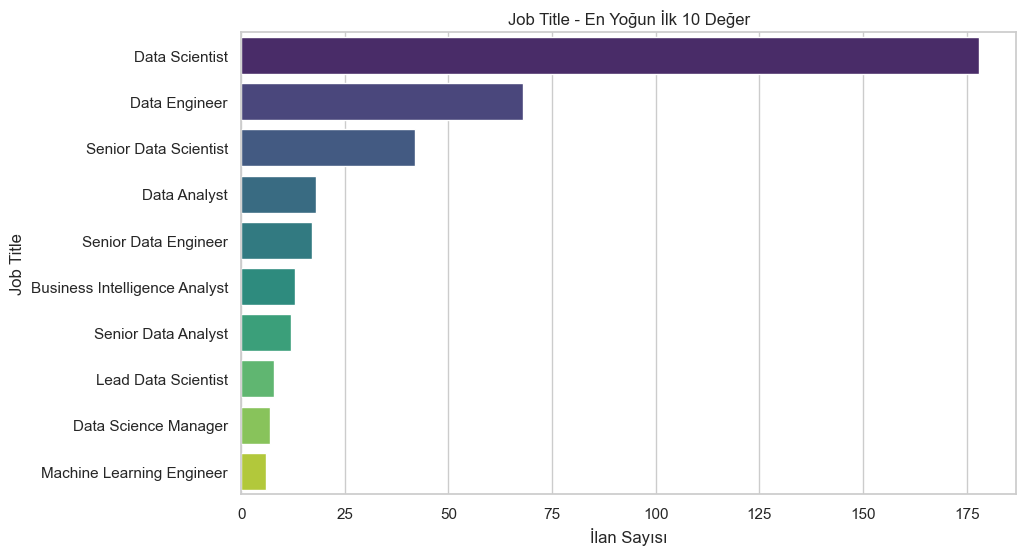

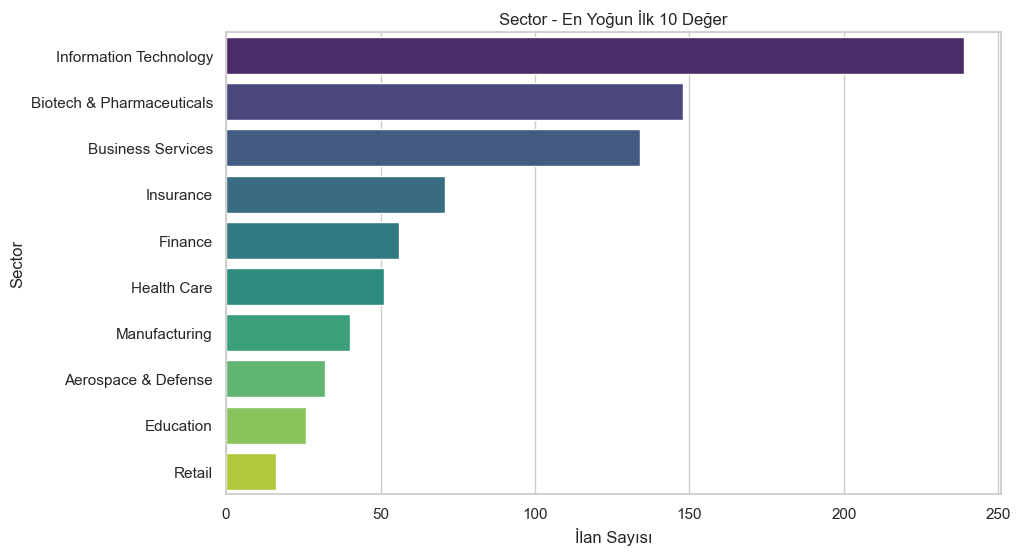

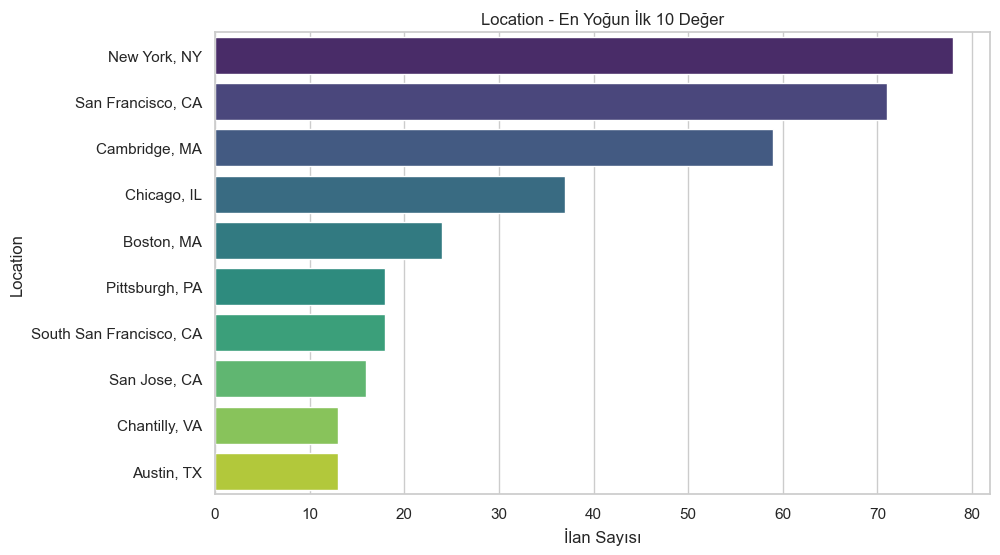

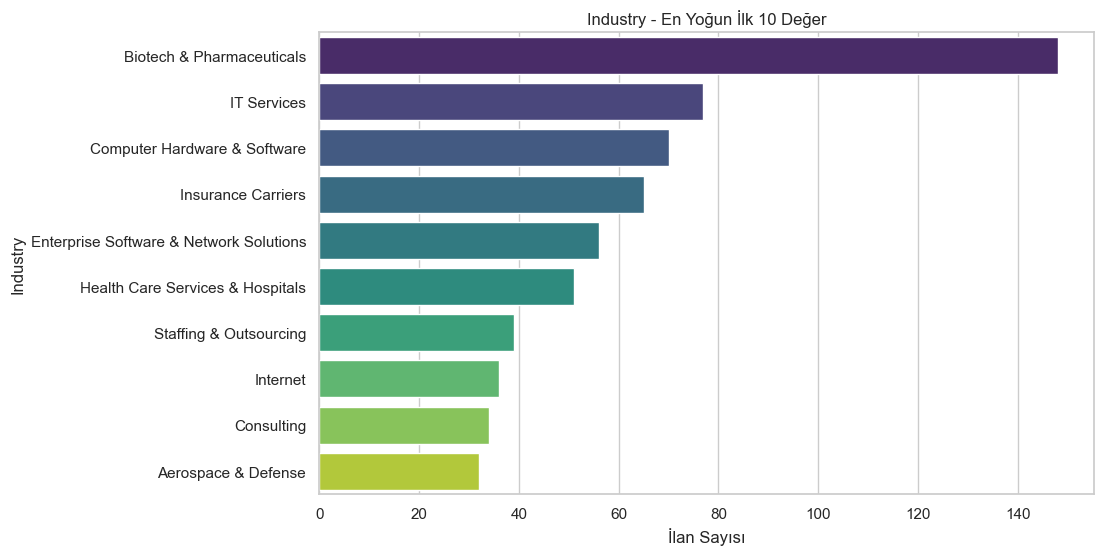

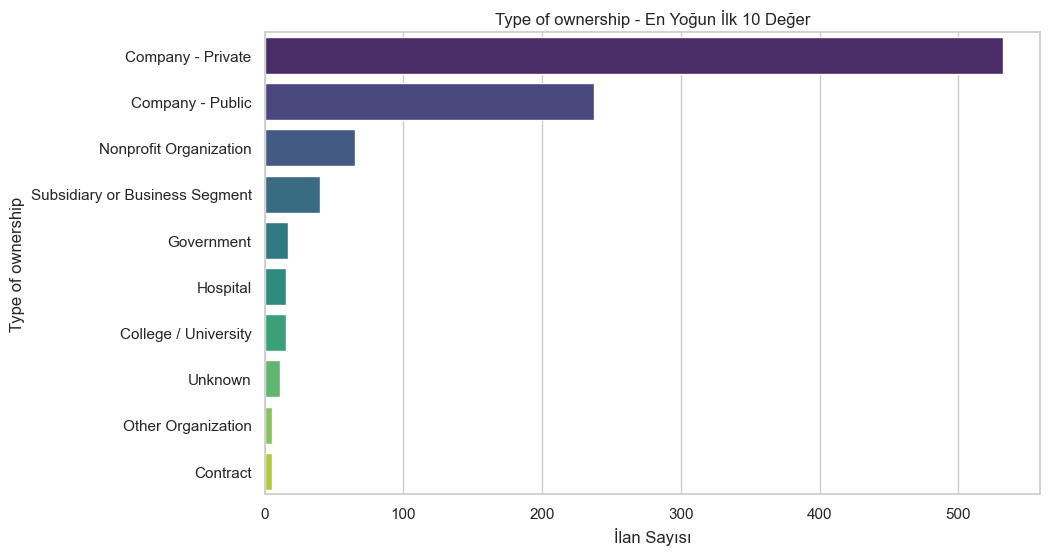

In [61]:
# Önemli kategorik sütunlar
cat_cols = ['Job Title', 'Sector', 'Location', 'Industry', 'Type of ownership']

for col in cat_cols:
    plt.figure(figsize=(10, 6))
    # En çok tekrar eden ilk 10 değeri al
    order = df[col].value_counts().head(10).index
    sns.countplot(data=df, y=col, order=order, palette='viridis')
    
    plt.title(f'{col} - En Yoğun İlk 10 Değer')
    plt.xlabel('İlan Sayısı')
    plt.ylabel(col)
    plt.show()

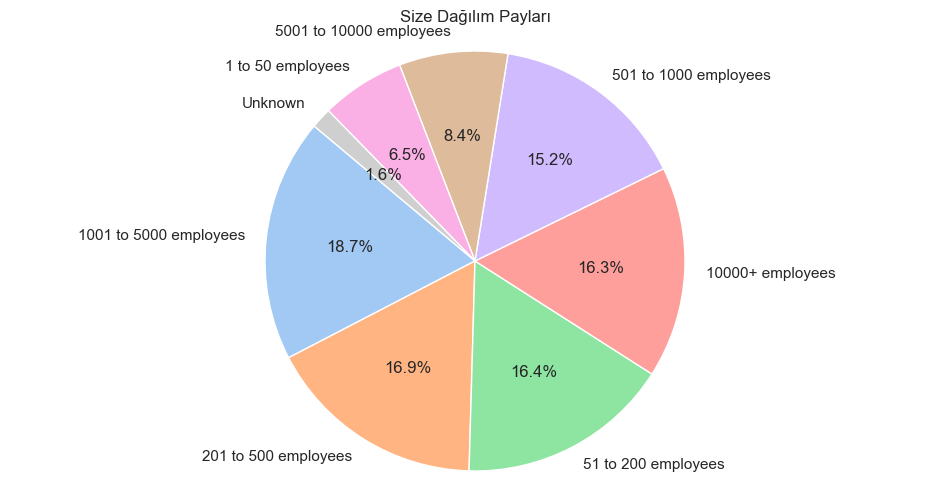

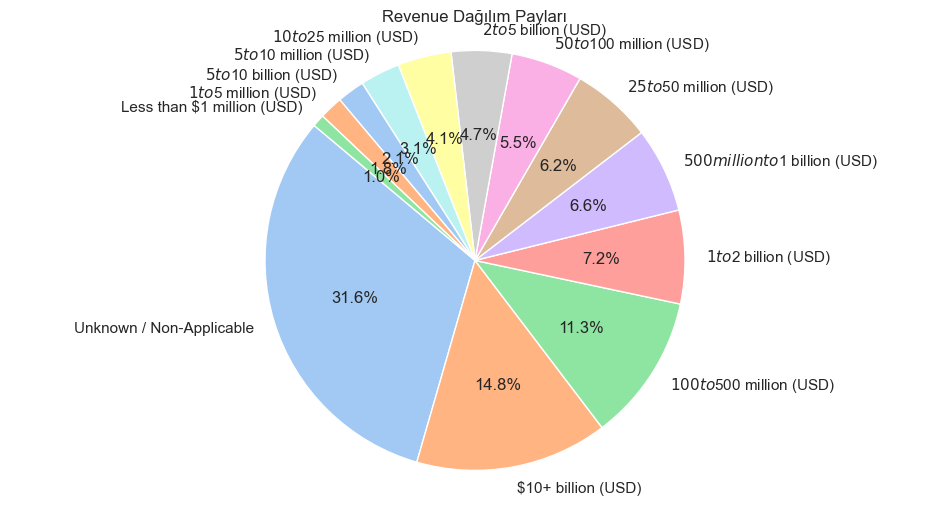

In [62]:
ordinal_cols = ['Size', 'Revenue']

for col in ordinal_cols:
    plt.figure(figsize=(12, 6))
    
    # Verideki benzersiz değerlerin sayılarını al
    val_counts = df[col].value_counts()
    
    # Pasta grafiği ile genel payı görelim
    plt.pie(val_counts, labels=val_counts.index, autopct='%1.1f%%', startangle=140, 
            colors=sns.color_palette('pastel'))
    
    plt.title(f'{col} Dağılım Payları')
    plt.axis('equal') 
    plt.show()

VERİDEKİ NaN değerleri analizlerimize göre dolduruyoruz.

In [63]:
df.drop(columns=['Competitors'], inplace=True)
founded_mode = df['Founded'].mode()[0]
df['Founded'] = df['Founded'].fillna(founded_mode)
df['Rating'] = df.groupby('Size')['Rating'].transform(lambda x: x.fillna(x.median() if not x.isnull().all() else df['Rating'].median()))

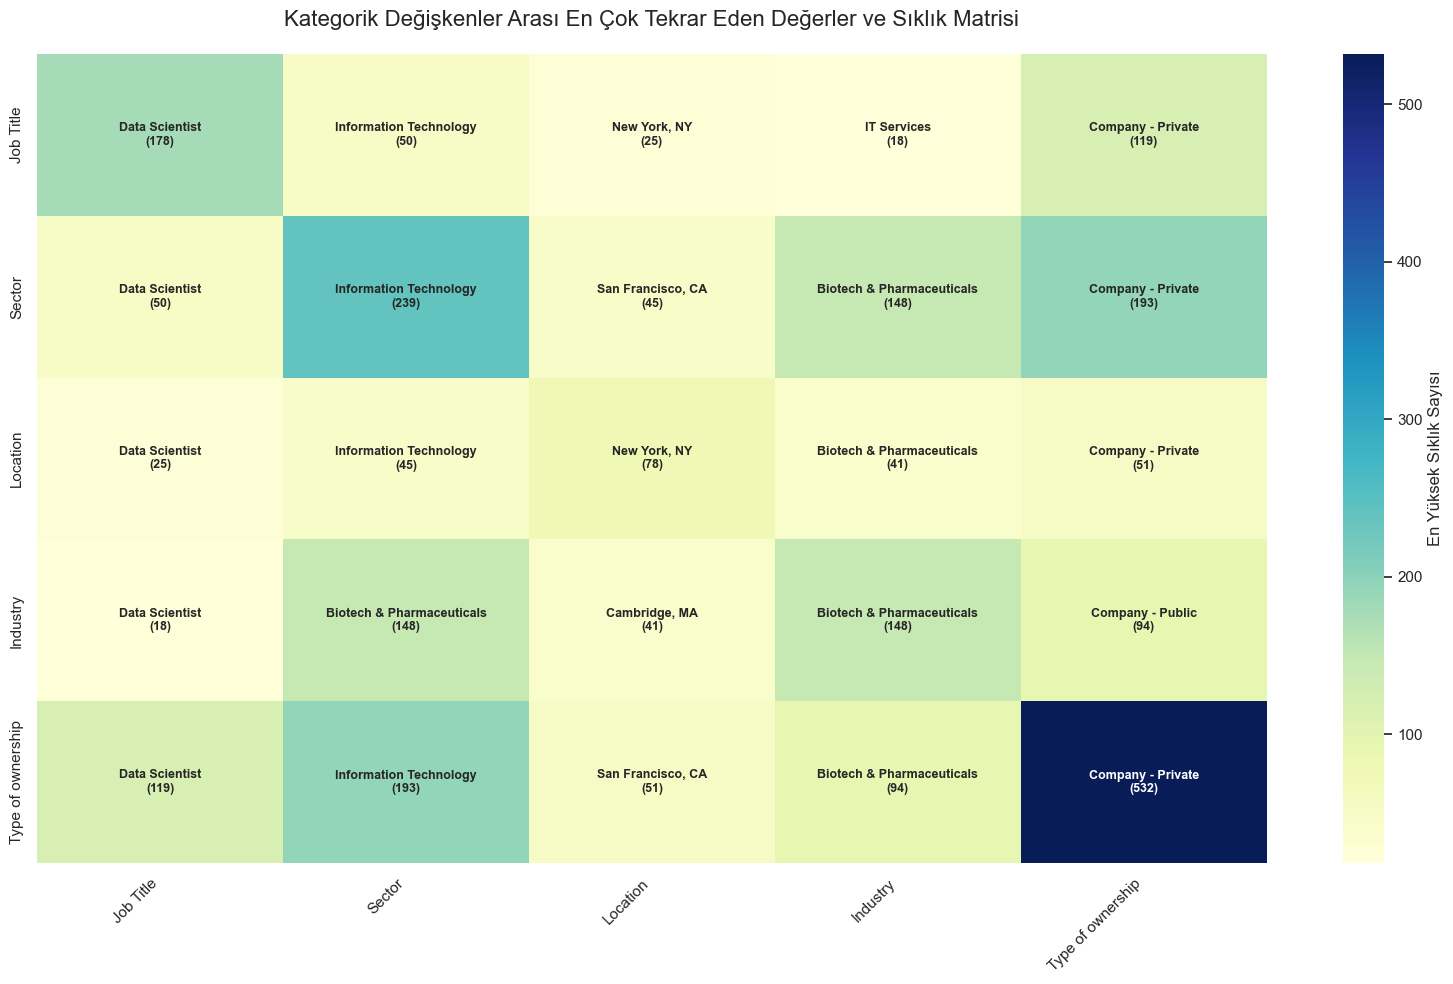

In [64]:
from itertools import product

# 1. Analiz edilecek sütunlar
cat_cols = ['Job Title', 'Sector', 'Location', 'Industry', 'Type of ownership']

# 2. Boş bir matris (DataFrame) oluşturalım
# Satırlar ve sütunlar kategorik değişken isimleri olacak
matrix_df = pd.DataFrame(index=cat_cols, columns=cat_cols)
annot_df = pd.DataFrame(index=cat_cols, columns=cat_cols) # İçine yazılacak metinler için

# 3. Tüm ikili kombinasyonları gezelim
for col1, col2 in product(cat_cols, repeat=2):
    if col1 == col2:
        # Aynı sütun kesiştiğinde o sütunun en çok tekrar eden değerini yazalım
        top_val = df[col1].mode()[0]
        count = df[col1].value_counts().iloc[0]
        matrix_df.loc[col1, col2] = count
        annot_df.loc[col1, col2] = f"{top_val}\n({count})"
    else:
        # İki farklı sütun kesiştiğinde en sık beraber görülen ikiliyi bulalım
        # Örn: NY lokasyonunda en çok hangi sektör var?
        top_pair = df.groupby([col1, col2]).size().idxmax()
        count = df.groupby([col1, col2]).size().max()
        
        matrix_df.loc[col1, col2] = count
        # Kesişme noktasına en çok tekrar eden değeri ve sayısını yazıyoruz
        annot_df.loc[col1, col2] = f"{top_pair[1]}\n({count})"

# 4. Görselleştirme
plt.figure(figsize=(16, 10))
# Sayısal değerleri matris üzerinden, metinleri annot_df üzerinden alıyoruz
sns.heatmap(matrix_df.astype(float), 
            annot=annot_df, 
            fmt="", 
            cmap="YlGnBu", 
            cbar_kws={'label': 'En Yüksek Sıklık Sayısı'},
            annot_kws={"size": 9, "weight": "bold"})

plt.title('Kategorik Değişkenler Arası En Çok Tekrar Eden Değerler ve Sıklık Matrisi', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Kategorik Veri Doldurma Stratejisi (İlişkisel Analiz)

Oluşturduğumuz **"Kategorik Değişkenler Arası En Çok Tekrar Eden Değerler ve Sıklık Matrisi"**, eksik verileri sadece basit bir "en çok tekrar eden" (mode) mantığıyla değil, değişkenler arasındaki **güçlü korelasyonları** kullanarak doldurmamıza olanak tanır.

## 1. Matris Üzerinden Önemli Çıkarımlar
Tablodaki yoğunlaşma noktaları, eksik verileri tahmin etmek için kullanacağımız temel dayanaklardır:

*   **İş Unvanı & Sektör:** Veri setindeki en baskın unvan olan **Data Scientist** (178 örnek), en sık **Information Technology** (50 örnek) sektörüyle eşleşmektedir.
*   **Sektör & Endüstri:** **Biotech & Pharmaceuticals** sektörü ile aynı isimli endüstri arasında %100'e yakın bir örtüşme (148 örnek) mevcuttur.
*   **Lokasyon & Sektör:** **San Francisco, CA** lokasyonundaki ilanların büyük çoğunluğu **Information Technology** (45 örnek) sektöründedir.
*   **Şirket Yapısı:** **Company - Private** türü, 532 örnek ile veri setinin genel karakteristiğini belirlemektedir.

## 2. Uygulanacak Doldurma (Imputation) Hiyerarşisi

### A. Koşullu Doldurma (Conditional Imputation)
1.  **Job Title** "Data Scientist" ise $\rightarrow$ **Sector** boşluğunu **Information Technology** ile doldur.
2.  **Sector** "Biotech & Pharmaceuticals" ise $\rightarrow$ **Industry** boşluğunu **Biotech & Pharmaceuticals** ile doldur.
3.  **Location** "New York, NY" ise $\rightarrow$ **Sector** boşluğunu **Information Technology** ile doldur.

### B. Genel Tamamlama
*   **Type of ownership:** Veri setinin genel modu olan **Company - Private** atanır.
*   **Diğer Durumlar:** Spesifik bir ilişki kurulamayan kalan tüm boşluklar için **"Unknown"** etiketi kullanılır.


In [65]:
# Job Title'a göre Sector doldurma
# 'Data Scientist' olanların boş sektörlerini 'Information Technology' ile doldurur
df['Sector'] = df.groupby('Job Title')['Sector'].transform(lambda x: x.fillna('Information Technology' if x.name == 'Data Scientist' else x.mode()[0] if not x.mode().empty else 'Unknown'))

#Sector'a göre Industry doldurma
# Sektörü 'Information Technology' olanların endüstrisini 'IT Services' (matristeki ilişkiye göre) yapar
df['Industry'] = df.groupby('Sector')['Industry'].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Unknown'))

# Lokasyona göre hala sektörde boş olanları doldurur
# Lokasyonu 'New York, NY' olan ve sektörü hala boş kalanları 'Information Technology' (45 örnek) ile doldurur
df.loc[(df['Location'] == 'New York, NY') & (df['Sector'].isnull()), 'Sector'] = 'Information Technology'

#  Genel mod ile kalanları dolduruyoruz.
df['Type of ownership'] = df['Type of ownership'].fillna('Company - Private')
df['Job Title'] = df['Job Title'].fillna('Data Scientist')

In [66]:
df.isnull().sum()

Unnamed: 0             0
Job Title              0
Salary Estimate      214
Job Description        0
Rating                11
Company Name           0
Location               0
Headquarters          11
Size                  11
Founded                0
Type of ownership      0
Industry               0
Sector                 0
Revenue               11
dtype: int64

KALAN BOŞ DEĞERLER AYNI GÖZLEM SATIRINDA MI DİYE KONTROL EDİYORUM.

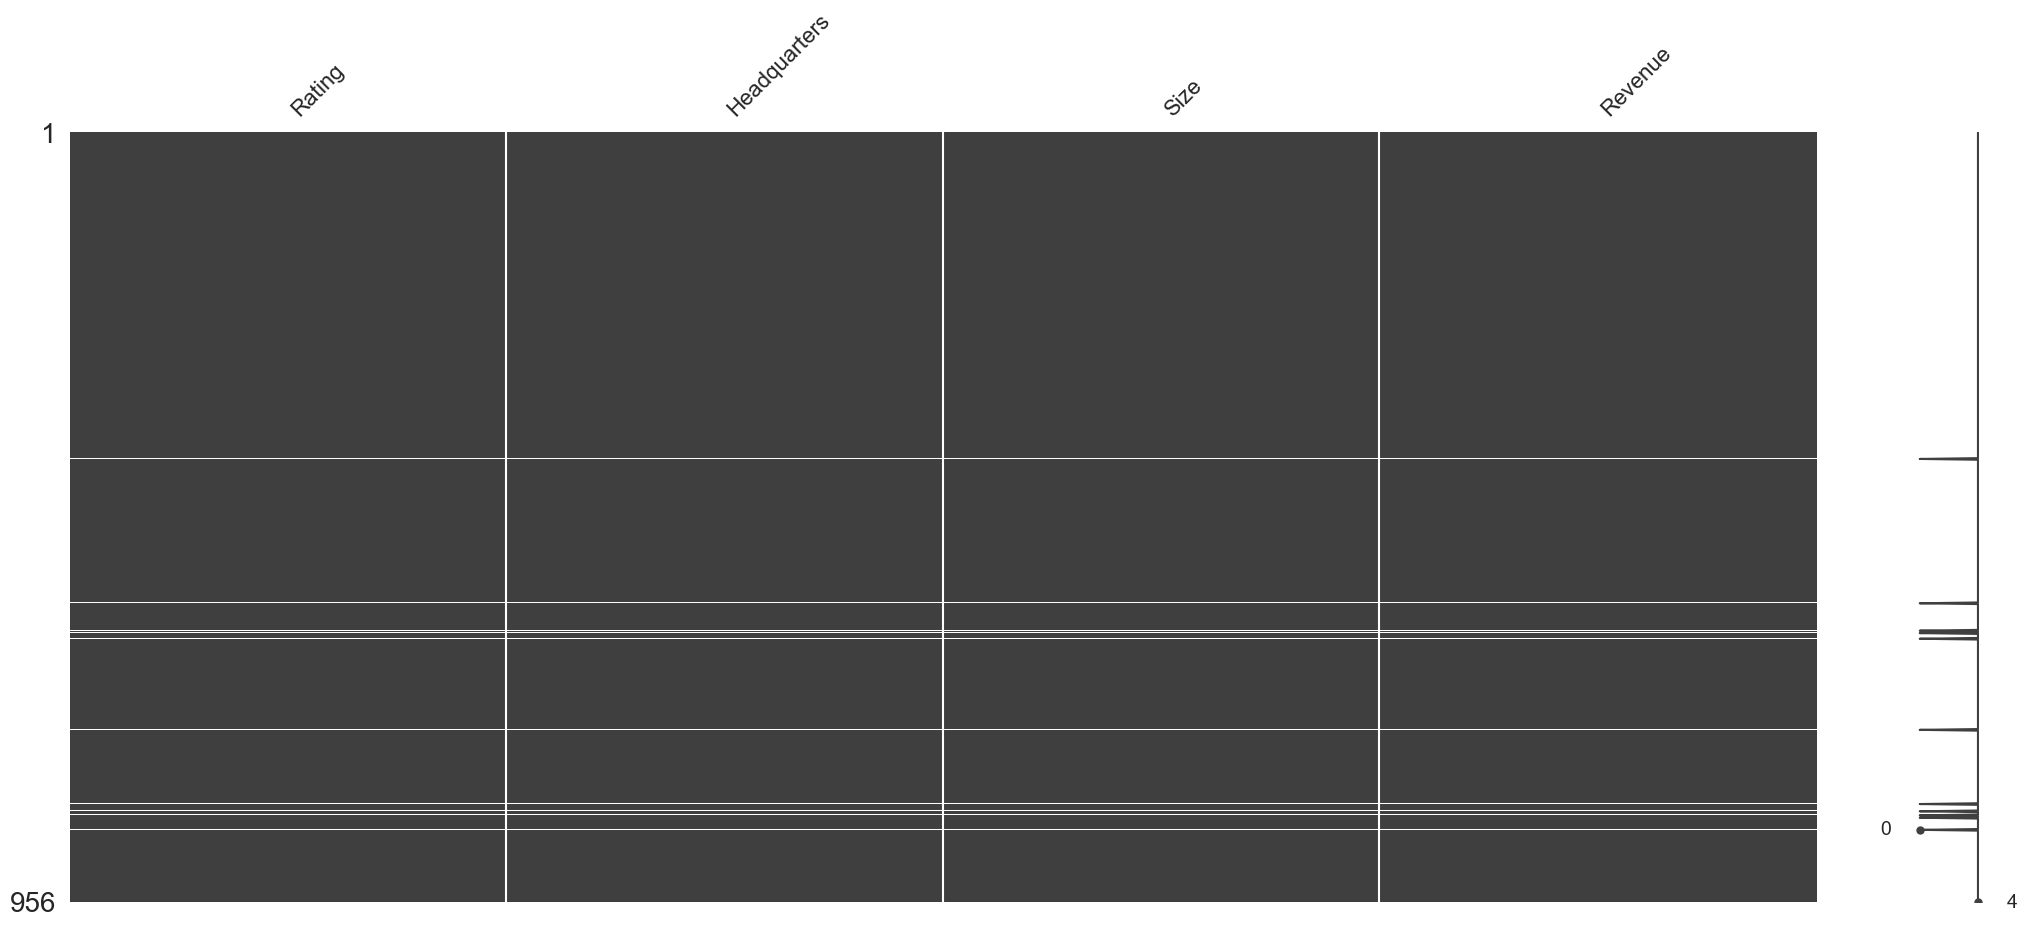

In [67]:
import missingno as msno
msno.matrix(df[['Rating', 'Headquarters', 'Size', 'Revenue']])
plt.show()

In [68]:
missing_rows = df[df['Rating'].isnull() & 
                 df['Headquarters'].isnull() & 
                 df['Size'].isnull() & 
                 df['Revenue'].isnull()]

display(missing_rows)
print(len(missing_rows))

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue
405,405,Scientist – Cancer Drug Discovery,NaN,Scientist – Cancer Drug Discovery\nLocation: C...,NaN,Monte Rosa Therapeutics,"Cambridge, MA",NaN,NaN,2008.0,Company - Private,Unknown,Unknown,NaN
584,584,Scientist – Cancer Drug Discovery,NaN,Scientist – Cancer Drug Discovery\nLocation: C...,NaN,Monte Rosa Therapeutics,"Cambridge, MA",NaN,NaN,2008.0,Company - Private,Unknown,Unknown,NaN
618,618,Data Scientist,NaN,This role requires you work closely with a var...,NaN,WeRide.ai,"San Jose, CA",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN
621,621,Data Scientist,NaN,This is a post on behalf of a hiring partner.\...,NaN,ODSC Hiring Partner,"New York, NY",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN
628,628,Data Scientist,NaN,About Our AI/ML Team\n\nOur mission is to buil...,NaN,Point72 Ventures,"Palo Alto, CA",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN
741,741,"Scientist – Cancer Discovery, Molecular Assay",Employer Provided Salary:$100K-$135K,"Scientist – Cancer Discovery, Molecular Assay\...",NaN,Monte Rosa Therapeutics,"Cambridge, MA",NaN,NaN,2008.0,Company - Private,Unknown,Unknown,NaN
833,833,Data Scientist,NaN,This role requires you work closely with a var...,NaN,WeRide.ai,"San Jose, CA",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN
842,842,Data Scientist,NaN,This is a post on behalf of a hiring partner.\...,NaN,ODSC Hiring Partner,"New York, NY",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN
847,847,Data Scientist,NaN,About Our AI/ML Team\n\nOur mission is to buil...,NaN,Point72 Ventures,"Palo Alto, CA",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN
850,850,Data Scientist,NaN,This is Adyen\n\nSpeed is the foundation of ou...,NaN,Adyen N.V.,"Amsterdam, NY",NaN,NaN,2008.0,Company - Private,IT Services,Information Technology,NaN


11


SALARY ESTİMATE BİZİM ETİKETİMİZ OLDUĞU İÇİN 214 NAN DEĞERİ SONRASINDA TAHMİN EDECEĞİZ.

KALAN NAN DEĞERLER İÇİN ANALİZ YAPIYORUZ.

In [69]:
df.dropna(subset=['Size'], inplace=True)

DEĞİŞKENLERDE SORUN VAR MI TEKRAR KONTROLLER SAĞLIYORUZ.

In [70]:
salary_counts = df['Salary Estimate'].value_counts(dropna=False)

print("Salary Estimate - Benzersiz Değerlerin Dağılımı:")
print(salary_counts.head(20))

Salary Estimate - Benzersiz Değerlerin Dağılımı:
Salary Estimate
NaN                                 204
$86K-$143K (Glassdoor est.)           6
$21-$34 Per Hour(Glassdoor est.)      6
$54K-$115K (Glassdoor est.)           6
$49K-$113K (Glassdoor est.)           6
$74K-$124K (Glassdoor est.)           5
$81K-$167K (Glassdoor est.)           5
$76K-$142K (Glassdoor est.)           5
$107K-$173K (Glassdoor est.)          5
$56K-$97K (Glassdoor est.)            4
$64K-$106K (Glassdoor est.)           4
$110K-$175K (Glassdoor est.)          4
$63K-$105K (Glassdoor est.)           4
$82K-$132K (Glassdoor est.)           4
$56K-$95K (Glassdoor est.)            4
$61K-$109K (Glassdoor est.)           4
$44K-$78K (Glassdoor est.)            4
$35K-$62K (Glassdoor est.)            4
$18-$25 Per Hour(Glassdoor est.)      4
$39K-$66K (Glassdoor est.)            4
Name: count, dtype: int64


yukarıda görmüş olunduğu üzere bazı gelirler saat cinsinden yazılmış. bunları yıllık fiyatlara çevirmek gerekecek. Değişkenimiz hala daha string.

In [71]:
per_hour_count = df['Salary Estimate'].str.contains('per hour', case=False, na=False).sum()

print(f"'Per Hour' (saatlik ücret) içeren toplam ilan sayısı: {per_hour_count}")


print("\nSaatlik ücret örnekleri:")
print(df[df['Salary Estimate'].str.contains('per hour', case=False, na=False)]['Salary Estimate'].head())

'Per Hour' (saatlik ücret) içeren toplam ilan sayısı: 24

Saatlik ücret örnekleri:
197    $17-$24 Per Hour(Glassdoor est.)
209    $21-$34 Per Hour(Glassdoor est.)
240    $18-$25 Per Hour(Glassdoor est.)
247    $21-$34 Per Hour(Glassdoor est.)
257    $15-$25 Per Hour(Glassdoor est.)
Name: Salary Estimate, dtype: str


BU GÖZLEMLERİ AYIRMAMIZ GEREKECEK BUNUN İÇİN BİR SĞTUN OLUŞTURUP BU TÜR PER HOUR İÇEREN GÖZLEMLERİN 1 DEĞERİNİ ALACAĞI is_hourly değişkeni yapıyoruz. SONRASINDA BURADAKİ SAATLİK DEĞERLERİ 

In [72]:
# Per hour olanlar 1, olmayanlar 0
df['is_hourly'] = df['Salary Estimate'].apply(lambda x: 1 if 'per hour' in str(x).lower() else 0)

# 2 Maaş metinlerini temizleyip 'average_salary' kolonu oluşturacağız
# Önce rakamları çekebilmek için metin temizliği yapıyoruz
cleaned_salary = df['Salary Estimate'].str.lower()
cleaned_salary = cleaned_salary.str.replace('employer provided salary:', '', regex=True)
cleaned_salary = cleaned_salary.str.replace('per hour', '', regex=True)
cleaned_salary = cleaned_salary.str.replace('$', '', regex=False).str.replace('k', '', regex=False)
cleaned_salary = cleaned_salary.apply(lambda x: str(x).split('(')[0].strip())

# Alt ve üst sınırları bulup ortalamasını alalım
def get_average(val):
    if '-' in val:
        parts = val.split('-')
        return (float(parts[0]) + float(parts[1])) / 2
    try:
        return float(val)
    except:
        return np.nan

df['average_salary'] = cleaned_salary.apply(get_average)

# 3. 'is_hourly' olanlara yıllık maaş formülü uygula (Update işlemi)
# Amerikan standartlarına göre: Saatlik Ücret * 2000 / 1000 (K birimi için) = Rakam * 2
df.loc[df['is_hourly'] == 1, 'average_salary'] = df['average_salary'] * 2

# 4. Sonuçları binlik birimden gerçek dolara çevirelim (Örn: 72 -> 72000)
df['average_salary'] = df['average_salary'] * 1000

# KONTROL
print(f"Toplam Saatlik İlan Sayısı: {df['is_hourly'].sum()}")
print("\nİşlem sonrası örnekler (Saatlik olanlar normalize edildi):")
print(df[df['is_hourly'] == 1][['Salary Estimate', 'is_hourly', 'average_salary']].head())

Toplam Saatlik İlan Sayısı: 24

İşlem sonrası örnekler (Saatlik olanlar normalize edildi):
                      Salary Estimate  is_hourly  average_salary
197  $17-$24 Per Hour(Glassdoor est.)          1         41000.0
209  $21-$34 Per Hour(Glassdoor est.)          1         55000.0
240  $18-$25 Per Hour(Glassdoor est.)          1         43000.0
247  $21-$34 Per Hour(Glassdoor est.)          1         55000.0
257  $15-$25 Per Hour(Glassdoor est.)          1         40000.0


In [73]:
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,is_hourly,average_salary
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973.0,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),0,72000.0
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984.0,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),0,87500.0
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010.0,Company - Private,Security Services,Business Services,$100 to $500 million (USD),0,85000.0
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965.0,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),0,76500.0
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998.0,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,0,114500.0


In [74]:
df.isnull().sum()

Unnamed: 0             0
Job Title              0
Salary Estimate      204
Job Description        0
Rating                 0
Company Name           0
Location               0
Headquarters           0
Size                   0
Founded                0
Type of ownership      0
Industry               0
Sector                 0
Revenue                0
is_hourly              0
average_salary       204
dtype: int64

ANCAK VERİDE UNKOWN OLARAK İŞARETLEDİĞİMİZ ANALİZLERİMİZ İLE DOLMAHAN DEĞİŞKENLER VARDI

In [75]:
size_dagilimi = df['Size'].value_counts(dropna=False)
print("Size Değişkeninin Değer Dağılımı:\n")
print(size_dagilimi)


benzersiz_deger_sayisi = df['Size'].nunique()
print(f"\nToplam benzersiz kategori sayısı: {benzersiz_deger_sayisi}")

Size Değişkeninin Değer Dağılımı:

Size
1001 to 5000 employees     177
201 to 500 employees       160
51 to 200 employees        155
10000+ employees           154
501 to 1000 employees      144
5001 to 10000 employees     79
1 to 50 employees           61
Unknown                     15
Name: count, dtype: int64

Toplam benzersiz kategori sayısı: 8


YUKARIDAKİ KONTROLÜ TÜM DEĞİŞKENLER İÇİN YAPIYORRUZ.

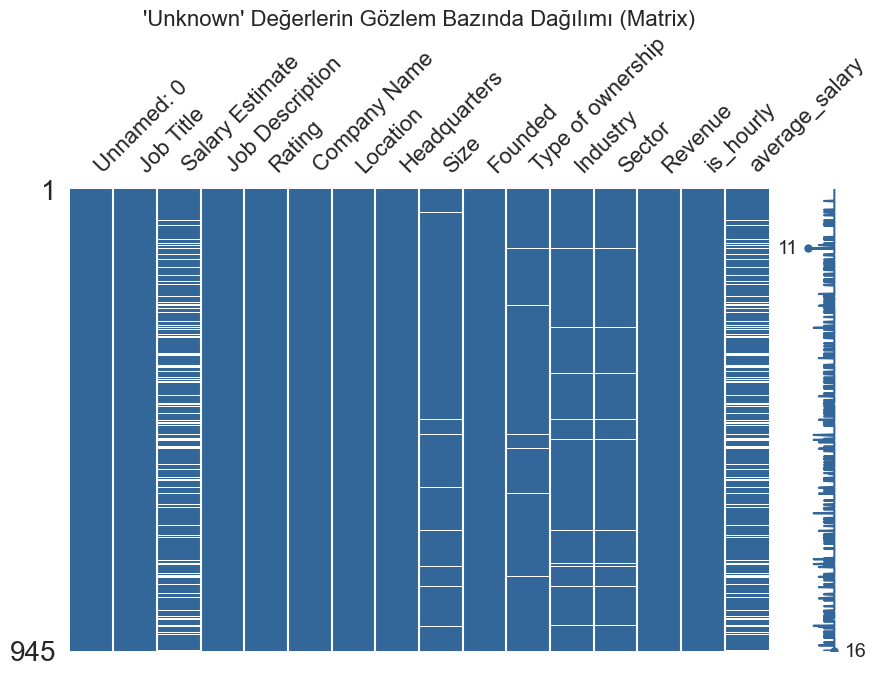

In [76]:
df_viz = df.replace('Unknown', np.nan)
msno.matrix(df_viz, figsize=(10, 6), color=(0.2, 0.4, 0.6))
plt.title("'Unknown' Değerlerin Gözlem Bazında Dağılımı (Matrix)", fontsize=16)
plt.show()

BAKTIĞIMIZDA BURADA INDUSTRY VE SECTOR ARASINDA KORELASYON VAR DİYE BİLİRİZ. BUNLARDAN BİR TANESİNİ SLECEĞİZ DİĞERLERİ İÇİN DE TYPE OF OWNERSHİP VE SECTOR İÇİN MODE A GÖRE DOLDURMA YAPACAĞIZ. 

In [77]:
df = df.replace('Unknown', np.nan)
df = df.drop('Industry', axis=1)
sector_modu = df['Sector'].mode()[0]
ownership_modu = df['Type of ownership'].mode()[0]

print(f"Sector için kullanılacak mod: '{sector_modu}'")
print(f"Type of ownership için kullanılacak mod: '{ownership_modu}'")

df['Sector'] = df['Sector'].fillna(sector_modu)
df['Type of ownership'] = df['Type of ownership'].fillna(ownership_modu)

# Temizlenmiş verinin son durumunu kontrol etmek için:
print("\nTemizleme sonrası kalan boş/NaN veri sayıları:")
print(df[['Sector', 'Type of ownership']].isnull().sum())

Sector için kullanılacak mod: 'Information Technology'
Type of ownership için kullanılacak mod: 'Company - Private'

Temizleme sonrası kalan boş/NaN veri sayıları:
Sector               0
Type of ownership    0
dtype: int64


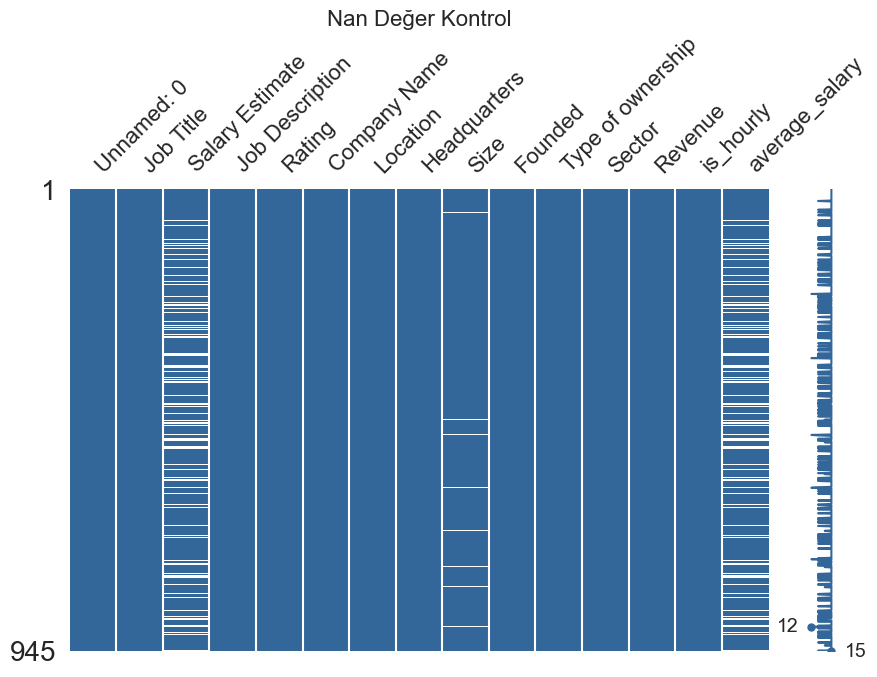

In [78]:
msno.matrix(df, figsize=(10, 6), color=(0.2, 0.4, 0.6))
plt.title("Nan Değer Kontrol", fontsize=16)
plt.show()

In [79]:
df['Size'] = df['Size'].replace('Unknown', np.nan)
global_size_mode = df['Size'].mode()[0]

df['Size'] = df.groupby('Headquarters')['Size'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else global_size_mode)
)

# 3. Kontrol
print(f"Kalan boş Size değeri sayısı: {df['Size'].isnull().sum()}")
print("Size sütunu başarıyla dolduruldu.")

Kalan boş Size değeri sayısı: 0
Size sütunu başarıyla dolduruldu.


In [80]:
df.isnull().sum()

Unnamed: 0             0
Job Title              0
Salary Estimate      204
Job Description        0
Rating                 0
Company Name           0
Location               0
Headquarters           0
Size                   0
Founded                0
Type of ownership      0
Sector                 0
Revenue                0
is_hourly              0
average_salary       204
dtype: int64

In [81]:
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Sector,Revenue,is_hourly,average_salary
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973.0,Company - Private,Aerospace & Defense,$50 to $100 million (USD),0,72000.0
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984.0,Other Organization,Health Care,$2 to $5 billion (USD),0,87500.0
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010.0,Company - Private,Business Services,$100 to $500 million (USD),0,85000.0
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965.0,Government,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),0,76500.0
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998.0,Company - Private,Business Services,Unknown / Non-Applicable,0,114500.0


ŞİMDİ VERİ SETİNDEKİ KULLANMAYACAĞIZ, BENZERLİK GÖSTEREN YA DA ANLAMSIZ DEĞİŞKENLERİ SİLİYORUZ. AVARAGE SALARYDE YER ALAN NaN DEĞERLERİ DE SONRA TAHMİNLEMEK ÜZERE SAKLIYORUZ.

In [82]:
sutunlar_silinecek = ['Unnamed:0', 'is_hourly', 'Salary Estimate', 'Job Description', 'Company Name']
df_cleaned = df.drop(columns=sutunlar_silinecek, errors='ignore')
df_model = df_cleaned[df_cleaned['average_salary'].notna()].copy()
df_tahmin_edilecek = df_cleaned[df_cleaned['average_salary'].isna()].copy()
print(f"Modelleme İçin Kullanılacak Veri Seti Boyutu (df_model): {df_model.shape}")
print(f"İleride Tahmin Edilecek Veri Seti Boyutu (df_tahmin_edilecek): {df_tahmin_edilecek.shape}")

Modelleme İçin Kullanılacak Veri Seti Boyutu (df_model): (741, 11)
İleride Tahmin Edilecek Veri Seti Boyutu (df_tahmin_edilecek): (204, 11)


In [83]:
df_model.head()

,Unnamed: 0,Job Title,Rating,Location,Headquarters,Size,Founded,Type of ownership,Sector,Revenue,average_salary
0,0,Data Scientist,3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973.0,Company - Private,Aerospace & Defense,$50 to $100 million (USD),72000.0
1,1,Healthcare Data Scientist,3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984.0,Other Organization,Health Care,$2 to $5 billion (USD),87500.0
2,2,Data Scientist,4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010.0,Company - Private,Business Services,$100 to $500 million (USD),85000.0
3,3,Data Scientist,3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965.0,Government,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),76500.0
4,4,Data Scientist,2.9,"New York, NY","New York, NY",51 to 200 employees,1998.0,Company - Private,Business Services,Unknown / Non-Applicable,114500.0


In [84]:
df_model = df_model.iloc[:, 1:]
df_model.head()

,Job Title,Rating,Location,Headquarters,Size,Founded,Type of ownership,Sector,Revenue,average_salary
0,Data Scientist,3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973.0,Company - Private,Aerospace & Defense,$50 to $100 million (USD),72000.0
1,Healthcare Data Scientist,3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984.0,Other Organization,Health Care,$2 to $5 billion (USD),87500.0
2,Data Scientist,4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010.0,Company - Private,Business Services,$100 to $500 million (USD),85000.0
3,Data Scientist,3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965.0,Government,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),76500.0
4,Data Scientist,2.9,"New York, NY","New York, NY",51 to 200 employees,1998.0,Company - Private,Business Services,Unknown / Non-Applicable,114500.0


In [85]:
df_tahmin_edilecek.head()

,Unnamed: 0,Job Title,Rating,Location,Headquarters,Size,Founded,Type of ownership,Sector,Revenue,average_salary
24,24,Data Scientist,3.9,Oregon,"Mc Lean, VA",10000+ employees,1911.0,Company - Private,Manufacturing,$10+ billion (USD),NaN
42,42,Data Scientist,4.1,"Chicago, IL","Chicago, IL",201 to 500 employees,2015.0,Company - Private,Information Technology,Unknown / Non-Applicable,NaN
47,47,Data Science Analyst,5.0,"Chandler, AZ","San Francisco, CA",51 to 200 employees,2017.0,Company - Private,Finance,Unknown / Non-Applicable,NaN
53,53,Data Engineer,4.5,"Kingdom, IL","London, United Kingdom",51 to 200 employees,2000.0,Company - Private,Business Services,$1 to $5 million (USD),NaN
64,64,Business Intelligence Analyst,3.1,"Lincoln, RI","Lincoln, RI",1001 to 5000 employees,1907.0,Company - Private,Insurance,$1 to $2 billion (USD),NaN


In [86]:
df_tahmin_edilecek = df_tahmin_edilecek.iloc[:, 1:]
df_tahmin_edilecek.head()

,Job Title,Rating,Location,Headquarters,Size,Founded,Type of ownership,Sector,Revenue,average_salary
24,Data Scientist,3.9,Oregon,"Mc Lean, VA",10000+ employees,1911.0,Company - Private,Manufacturing,$10+ billion (USD),NaN
42,Data Scientist,4.1,"Chicago, IL","Chicago, IL",201 to 500 employees,2015.0,Company - Private,Information Technology,Unknown / Non-Applicable,NaN
47,Data Science Analyst,5.0,"Chandler, AZ","San Francisco, CA",51 to 200 employees,2017.0,Company - Private,Finance,Unknown / Non-Applicable,NaN
53,Data Engineer,4.5,"Kingdom, IL","London, United Kingdom",51 to 200 employees,2000.0,Company - Private,Business Services,$1 to $5 million (USD),NaN
64,Business Intelligence Analyst,3.1,"Lincoln, RI","Lincoln, RI",1001 to 5000 employees,1907.0,Company - Private,Insurance,$1 to $2 billion (USD),NaN


DEĞİŞKENLERİN DÖNÜŞTÜRECEĞİZ İSTEDİĞİMİZ TARZA

In [87]:
# Veri setindeki Glassdoor klasikleri olan -1 değerlerini NaN yapalım
df_model['Founded'] = df_model['Founded'].replace([-1, -1.0, '-1'], np.nan)

# Şirket yaşını hesaplayalım (Bulunduğumuz yıl olan 2026'yı baz alarak)
df_model['Company_Age'] = 2026 - df_model['Founded']

# Yaşı eksik olan şirketleri, diğer şirketlerin medyan yaşı ile doldurabiliriz
df_model['Company_Age'] = df_model['Company_Age'].fillna(df_model['Company_Age'].median())

# Artık 'Founded' sütununa ihtiyacımız kalmadı, veri setinden atabiliriz
df_model = df_model.drop(columns=['Founded'])

In [88]:
# 1. df_tahmin_edilecek için -1 değerlerini NaN yapalım
df_tahmin_edilecek['Founded'] = df_tahmin_edilecek['Founded'].replace([-1, -1.0, '-1'], np.nan)

# 2. Şirket yaşını hesaplayalım (2026 baz alınarak)
df_tahmin_edilecek['Company_Age'] = 2026 - df_tahmin_edilecek['Founded']

# 3. Eksik yaşları df_model'in medyanı ile dolduralım (Kritik Adım)
model_medyan_yas = df_model['Company_Age'].median()
df_tahmin_edilecek['Company_Age'] = df_tahmin_edilecek['Company_Age'].fillna(model_medyan_yas)

# 4. 'Founded' sütununu df_tahmin_edilecek'ten atalım
df_tahmin_edilecek = df_tahmin_edilecek.drop(columns=['Founded'])

In [89]:
print(df_model['Size'].unique())
print(f"Toplam benzersiz kategori sayısı: {df_model['Size'].nunique()}")

<StringArray>
[  '501 to 1000 employees',        '10000+ employees',
  '1001 to 5000 employees',     '51 to 200 employees',
    '201 to 500 employees', '5001 to 10000 employees',
       '1 to 50 employees']
Length: 7, dtype: str
Toplam benzersiz kategori sayısı: 7


In [90]:
# Şirket boyutlarını küçükten büyüğe doğru numaralandıran bir sözlük (mapping)
size_mapping = {
    '1 to 50 employees': 1,
    '51 to 200 employees': 2,
    '201 to 500 employees': 3,
    '501 to 1000 employees': 4,
    '1001 to 5000 employees': 5,
    '5001 to 10000 employees': 6,
    '10000+ employees': 7
}

# map() fonksiyonu ile string değerleri sayısal değerlere dönüştürüyoruz
df_model['Size'] = df_model['Size'].map(size_mapping)

# Aynı işlemi ileride tahmin edeceğimiz veri seti için de yapıyoruz
df_tahmin_edilecek['Size'] = df_tahmin_edilecek['Size'].map(size_mapping)

print("Size değişkeni başarıyla sayısallaştırıldı!")
print(df_model['Size'].head())

Size değişkeni başarıyla sayısallaştırıldı!
0    4
1    7
2    4
3    5
4    2
Name: Size, dtype: int64


In [91]:
df_model['Revenue'] = df_model['Revenue'].replace('Unknown / Non-Applicable', np.nan)
global_revenue_mode = df_model['Revenue'].mode()[0]

df_model['Revenue'] = df_model.groupby('Size')['Revenue'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else global_size_mode)
)

# 3. Kontrol
print(f"Kalan boş Size değeri sayısı: {df_model['Revenue'].isnull().sum()}")
print("Size sütunu başarıyla dolduruldu.")

Kalan boş Size değeri sayısı: 0
Size sütunu başarıyla dolduruldu.


In [92]:
df_tahmin_edilecek['Revenue'] = df_tahmin_edilecek['Revenue'].replace('Unknown / Non-Applicable', np.nan)
global_revenue_mode = df_tahmin_edilecek['Revenue'].mode()[0]

df_tahmin_edilecek['Revenue'] = df_tahmin_edilecek.groupby('Size')['Revenue'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else global_size_mode)
)

# 3. Kontrol
print(f"Kalan boş Size değeri sayısı: {df_tahmin_edilecek['Revenue'].isnull().sum()}")
print("Size sütunu başarıyla dolduruldu.")

Kalan boş Size değeri sayısı: 0
Size sütunu başarıyla dolduruldu.


In [93]:
print(df_model['Revenue'].unique())
print(f"Toplam benzersiz kategori sayısı: {df_model['Revenue'].nunique()}")

<StringArray>
[       '$50 to $100 million (USD)',           '$2 to $5 billion (USD)',
       '$100 to $500 million (USD)', '$500 million to $1 billion (USD)',
         '$10 to $25 million (USD)',           '$1 to $2 billion (USD)',
         '$25 to $50 million (USD)',               '$10+ billion (USD)',
           '$1 to $5 million (USD)',          '$5 to $10 billion (USD)',
       'Less than $1 million (USD)',          '$5 to $10 million (USD)']
Length: 12, dtype: str
Toplam benzersiz kategori sayısı: 12


In [94]:
import pandas as pd
import numpy as np

def categorize_revenue(res_str):
    if pd.isna(res_str) or 'Unknown' in res_str:
        return np.nan
    
    # Metni temizle ve sayıları ayıkla
    # Milyar (billion) kelimesi geçiyorsa sayıları 1000 ile çarpıyoruz (Milyon bazında eşitleme)
    multiplier = 1000 if 'billion' in res_str else 1
    import re
    nums = re.findall(r'\d+', res_str.replace(',', ''))
    
    if not nums:
        return np.nan
    
    # Aralık verilerinde üst sınırı (max) baz almak gruplandırma için daha sağlıklıdır
    val = float(nums[-1]) * multiplier 

    # Senin kriterlerine göre Ordinal Gruplandırma
    if val <= 100:
        return 1  # 100 Milyon ve altı
    elif val <= 500:
        return 2  # 500 Milyon ve altı
    elif val <= 1000:
        return 3  # 1 Milyar (1000M) ve altı
    elif val <= 10000:
        return 4  # 10 Milyar (10000M) ve altı
    else:
        return 5  # 10 Milyar üstü

# Dönüşümü uygula
df_model['Revenue'] = df_model['Revenue'].apply(categorize_revenue)
df_tahmin_edilecek['Revenue']=df_tahmin_edilecek['Revenue'].apply(categorize_revenue)

# Kontrol edelim
print(df_model[['Revenue']].drop_duplicates())
print(df_tahmin_edilecek[['Revenue']].drop_duplicates())

   Revenue
0        1
1        4
2        2
3        3
     Revenue
24         4
42         1
151        2
227        3


In [95]:
df_model.head()

,Job Title,Rating,Location,Headquarters,Size,Type of ownership,Sector,Revenue,average_salary,Company_Age
0,Data Scientist,3.8,"Albuquerque, NM","Goleta, CA",4,Company - Private,Aerospace & Defense,1,72000.0,53.0
1,Healthcare Data Scientist,3.4,"Linthicum, MD","Baltimore, MD",7,Other Organization,Health Care,4,87500.0,42.0
2,Data Scientist,4.8,"Clearwater, FL","Clearwater, FL",4,Company - Private,Business Services,2,85000.0,16.0
3,Data Scientist,3.8,"Richland, WA","Richland, WA",5,Government,"Oil, Gas, Energy & Utilities",3,76500.0,61.0
4,Data Scientist,2.9,"New York, NY","New York, NY",2,Company - Private,Business Services,1,114500.0,28.0


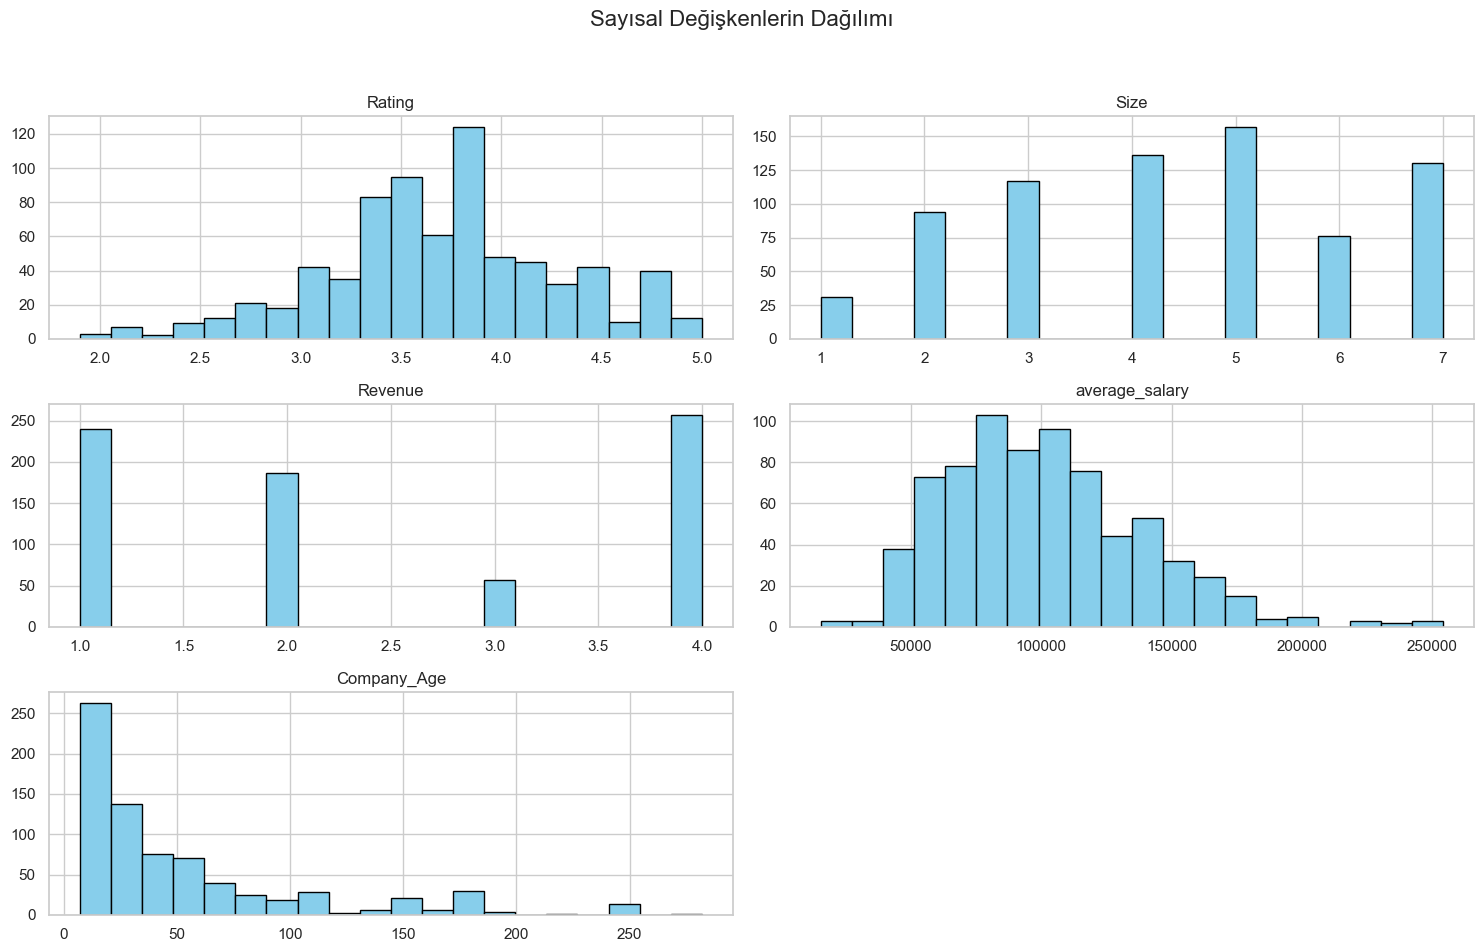

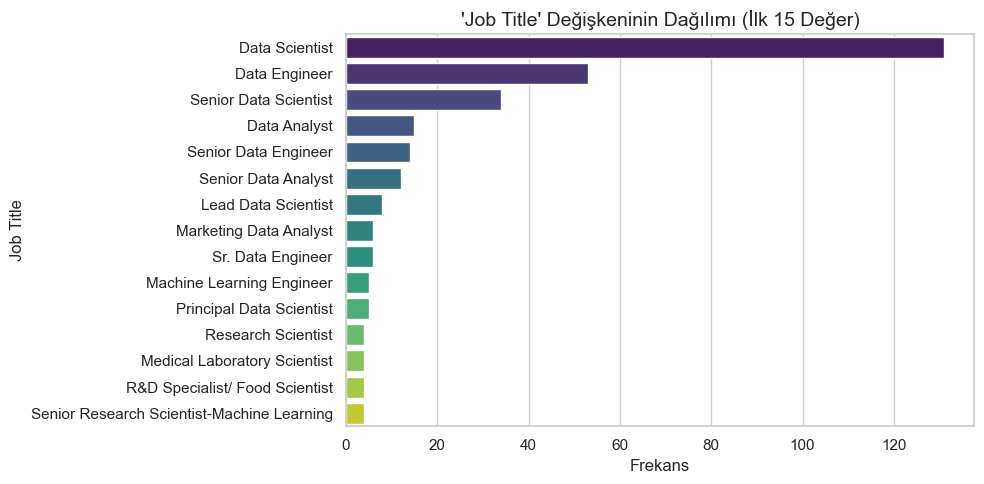

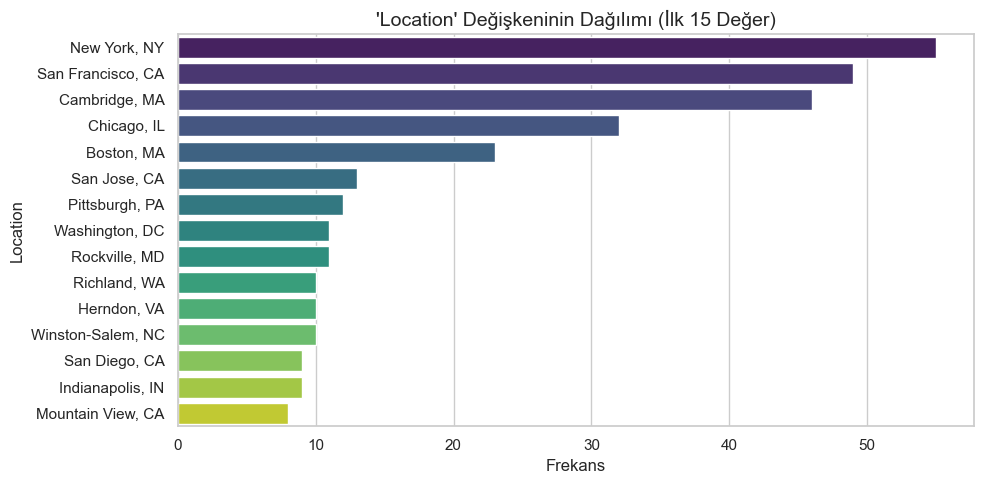

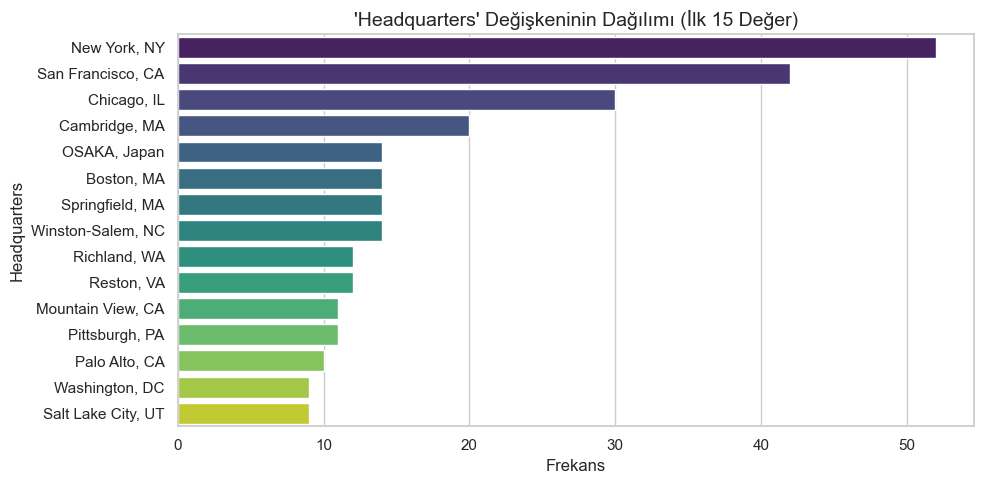

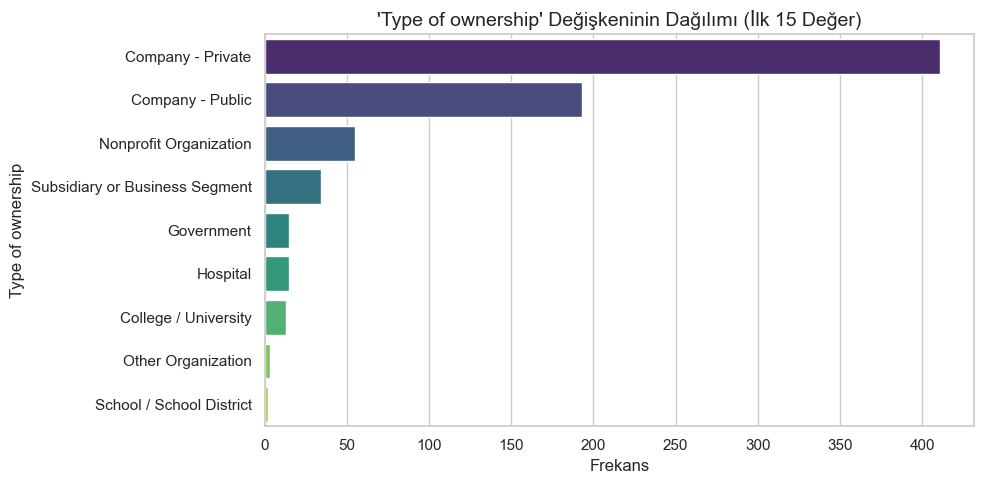

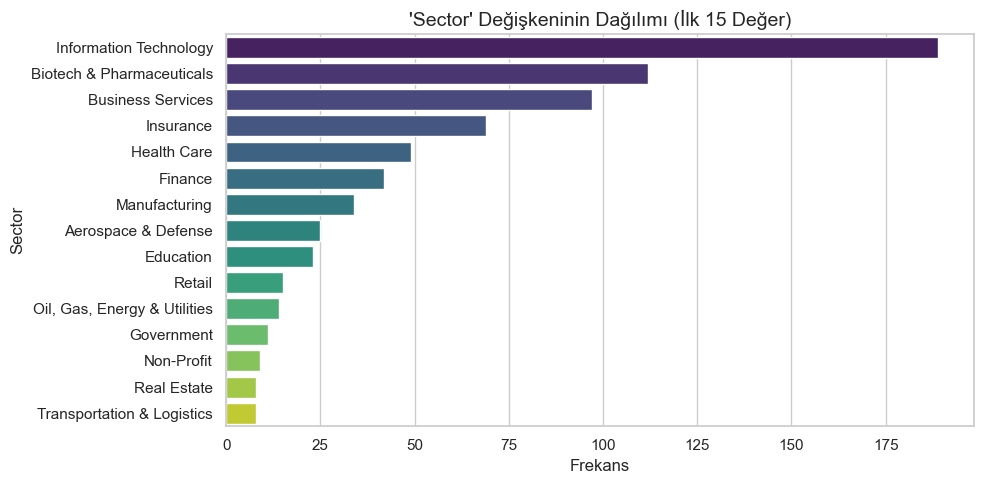

In [96]:
# Grafik stilini ayarlayalım
sns.set_theme(style="whitegrid")

# --- 1. Sayısal Değişkenlerin Dağılımı (Histogram) ---
sayisal_sutunlar = df_model.select_dtypes(exclude=['object']).columns

# Eğer sayısal sütun varsa çizdir
if len(sayisal_sutunlar) > 0:
    df_model[sayisal_sutunlar].hist(figsize=(15, 10), bins=20, color='skyblue', edgecolor='black')
    plt.suptitle("Sayısal Değişkenlerin Dağılımı", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- 2. Kategorik Değişkenlerin Dağılımı (Bar Chart) ---
kategorik_sutunlar = df_model.select_dtypes(include=['object']).columns

for kolon in kategorik_sutunlar:
    plt.figure(figsize=(10, 5))
    
    # En çok tekrar eden ilk 15 kategoriyi alıyoruz (grafik çok kalabalık olmasın diye)
    sns.countplot(
        y=kolon, 
        data=df_model, 
        order=df_model[kolon].value_counts().iloc[:15].index,
        palette="viridis"
    )
    
    plt.title(f"'{kolon}' Değişkeninin Dağılımı (İlk 15 Değer)", fontsize=14)
    plt.xlabel("Frekans")
    plt.ylabel(kolon)
    plt.tight_layout()
    plt.show()

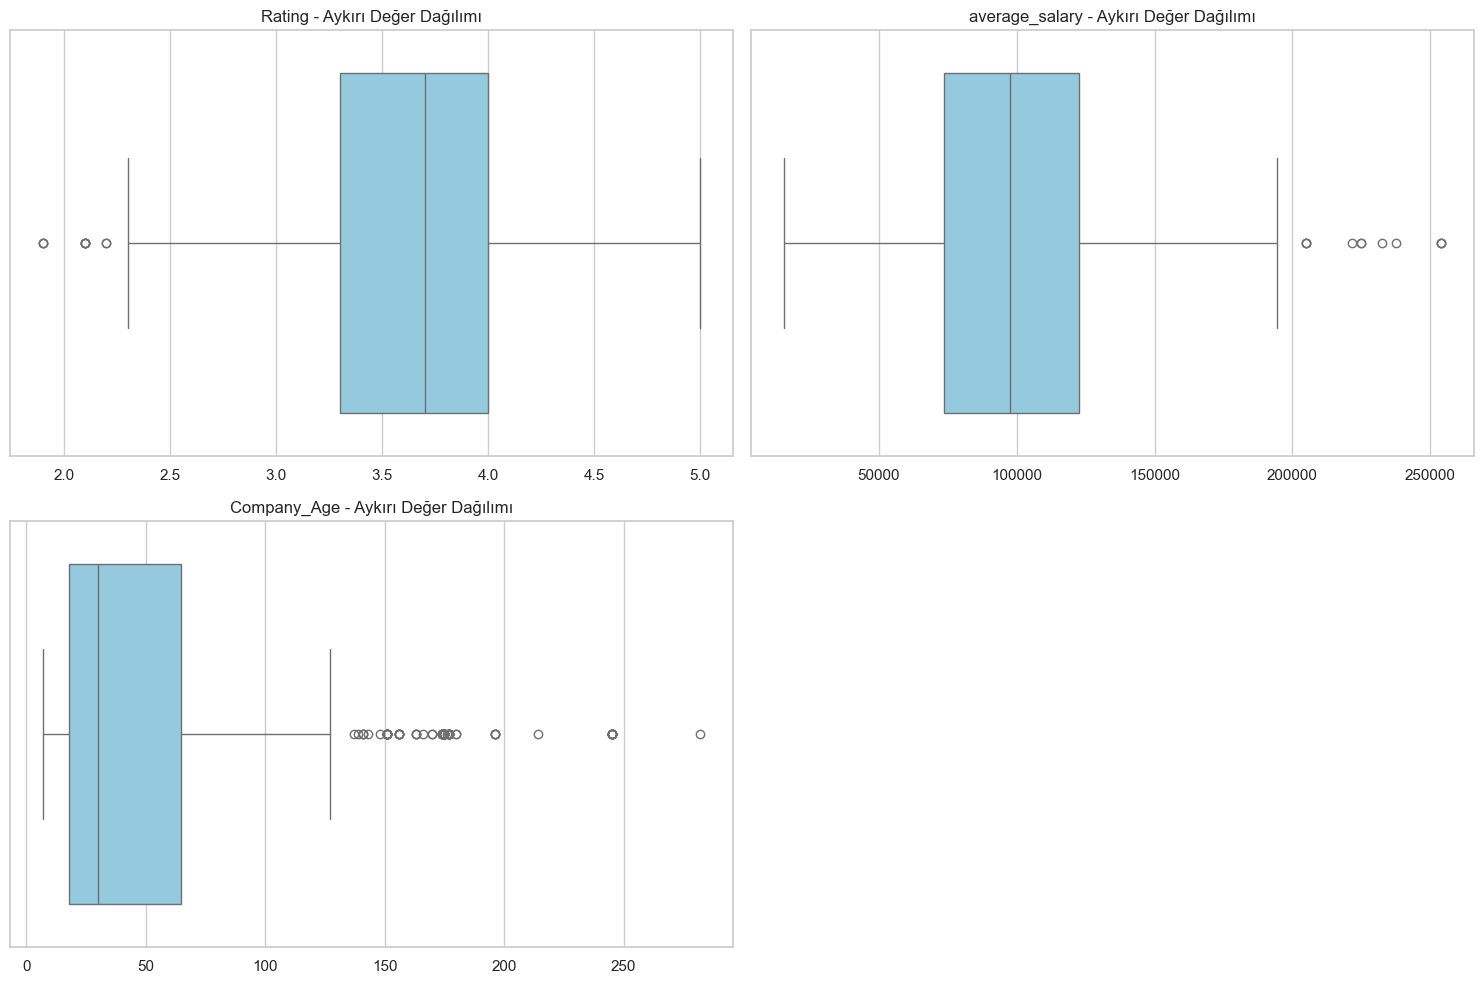

In [97]:
sayisal_degiskenler = ['Rating', 'average_salary', 'Company_Age']

# Çoklu grafik alanı oluşturma
plt.figure(figsize=(15, 10))

for i, col in enumerate(sayisal_degiskenler, 1):
    plt.subplot(2, 2, i) # 2x2'lik bir grafik ızgarası
    sns.boxplot(x=df_model[col], color='skyblue')
    plt.title(f'{col} - Aykırı Değer Dağılımı', fontsize=12)
    plt.xlabel('') 

plt.tight_layout()
plt.show()

Eğitim Setinde Veri Çoğaltma (Data Augmentation) Stratejisi

### 🔹 Sorun (Veri Seyrekliği)
Veri setinde bazı unvanlar (`Job Title`) veya niş sektörler (`Sector`) çok az sayıda örneğe sahiptir. Model, bu azınlık sınıfları doğrudan öğrenmeye çalıştığında ya bu rollerin pazar dinamiklerini gözden kaçırmakta (underfitting) ya da o birkaç örneği birebir ezberlemektedir (overfitting).

### 🔹 Çözüm (Gürültülü Sentetik Çoğaltma)
Sürekli değişken tahminleme (Regresyon) problemlerinde klasik sınıflandırma çoğaltma yöntemleri (standart SMOTE gibi) doğrudan kullanılamaz. Geliştirilen mimaride, eğitim setindeki azınlık unvanlar tespit edilerek kopyalanmış; ancak ağaç tabanlı modellerin bu kopyaları ezberlemesini önlemek için şirketin yaşı, reytingi gibi sayısal değişkenlere (`num_cols`) küçük oranda rastgele gürültü eklenmiştir:

$$X_{\text{yeni}} = X_{\text{orijinal}} + \mathcal{N}(0, \sigma \cdot \text{std}(X))$$

> ⚠️ **Veri Sızıntısı Güvenliği:** Bu işlem kesinlikle `train_test_split` adımından sonra, el değmemiş test verisini korumak adına **sadece** eğitim veri seti (`X_train`, `y_train`) üzerinde uygulanmıştır.

---

## 2. Model Çeşitliliği (Algoritmik Mimari)

Tek bir algoritmanın ön yargısına (bias) bağlı kalmamak adına, gradyan tabanlı öğrenmede farklı karakterlere sahip **3 güçlü makine öğrenmesi algoritması** yarışmıştır:

1. **XGBoost (Hist):** Seviye bazlı (level-wise) derinleşen, histogram tabanlı eşik değer aramasıyla hızlı ve dengeli çalışan sektör standardı doğrusal boosting mimarisi.
2. **LightGBM (GBDT):** Yaprak bazlı (leaf-wise) büyüme stratejisiyle çalışan, yüksek varyanslı verileri çok daha agresif çözen ve kategorik veri tiplerini yerleşik olarak işleyebilen yüksek performanslı algoritma.
3. **LightGBM (DART):** Derin Öğrenme'deki (Deep Learning) *Dropout* mantığını karar ağaçlarına uygular. Her iterasyonda mevcut ağaçların belirli bir yüzdesini rastgele devre dışı bırakarak (drop) sonraki ağaçların aşırı baskın olmasını engeller. Bu yöntem, piyasada çok nadir karşılaşılan aday profillerinde modelin genellenebilirliğini (generalization) maksimuma çıkarır.

---

## 3. Matematiksel Kayıp Fonksiyonları (Loss Functions) ve Kurumsal İK Dinamikleri

Modelin pazar gerçeklerini öğrenme biçimi, şirketin risk iştahına ve bütçe politikalarına göre **4 farklı kayıp fonksiyonu** ile yönlendirilmiştir. Hata miktarı $x = \hat{y} - y$ (Tahmin - Gerçek) olmak üzere fonksiyonların matematiksel altyapıları şu şekildedir:

### 3.1. Mean Absolute Error (MAE) - *Geleneksel Yaklaşım*
* **Matematiksel Formül:** $$L(y, \hat{y}) = |y - \hat{y}|$$
* **İK Stratejisi:** Hataları mutlak fark olarak ele alır. Bütçeyi 5.000\$ fazla tahmin etmek ile 5.000\$ eksik tahmin etmek model gözünde tamamen eşit cezalandırılır. Pazar ortalamasını şeffaf ve doğrusal olarak izlemek için temel (baseline) metriktir.

### 3.2. Fair Loss (Adil Kayıp) - *Uç Değer (Outlier) Toleransı*
* **Matematiksel Formül:** $$L(x) = c \cdot |x| - c^2 \ln\left(1 + \frac{|x|}{c}\right)$$
* **Birinci Türevi (Gradient):** $$g = \frac{c \cdot x}{|x| + c}$$
* **İkinci Türevi (Hessian):** $$h = \frac{c^2}{(|x| + c)^2}$$
* **İK Stratejisi:** Maaş verilerinde C-Level yöneticiler veya niş uzmanlar pazar ortalamasının çok üstünde kazanabilir. Standart karesel hata (MSE) bu uç değerleri görünce gradyanları patlatır ve modeli saptırır. `Fair Loss`, hata ($x$) küçükken karesel (smooth), hata büyüdükçe doğrusal (linear) davranarak bu uç maaşların pazarın genel tahmin kalitesini bozmasını engeller.

### 3.3. Mean Squared Logarithmic Error (MSLE) - *İç Adalet ve Oransal Ceza*
* **Matematiksel Formül:** $$L(y, \hat{y}) = \Big(\ln(1 + \hat{y}) - \ln(1 + y)\Big)^2$$
* **İK Stratejisi:** Hatanın dolar bazındaki büyüklüğüne değil, **yüzdesel oranına** odaklanır. Yeni mezun bir pozisyonda 40.000\$ yerine 50.000\$ teklif etmek (10.000\$ hata = %25 sapma) büyük bir bütçe ihlalidir. Ancak bir direktör pozisyonunda 180.000\$ yerine 190.000\$ teklif etmek (10.000\$ hata = %5.5 sapma) kabul edilebilir bir pazarlık payıdır. MSLE, düşük maaş gruplarındaki oransal sapmaları daha sert cezalandırarak şirket içi maaş dengesini ve adaletini korur.

### 3.4. Asymmetric Loss (Asimetrik Kayıp) - *Yetenek Kaybı ve Boş Kadro Maliyeti*
* **Matematiksel Formül (Gradyan Tabanlı Yaklaşım):**
    $$\text{Gradient} = \begin{cases} -3.0 \cdot (\hat{y} - y), & \text{eğer } \hat{y} < y \quad \text{(Eksik Tahmin)} \\ 1.0 \cdot (\hat{y} - y), & \text{eğer } \hat{y} \ge y \quad \text{(Fazla Tahmin)} \end{cases}$$
    $$\text{Hessian} = \begin{cases} 3.0, & \text{eğer } \hat{y} < y \\ 1.0, & \text{eğer } \hat{y} \ge y \end{cases}$$
* **İK Stratejisi:** İşe alım süreçlerinde "Boş Pozisyon Maliyeti" (Cost of Vacancy) kritik bir risk unsurudur. Model bir adayın hak ettiği maaşı piyasanın altında tahmin ederse (`eksik tahmin`), aday teklifi reddeder ve şirket kritik bir yeteneği rakiplerine kaptırır. Eğer piyasanın biraz üstünde tahmin ederse (`fazla tahmin`), sadece bütçe hafifçe esner. Bu asimetrik fonksiyon, eksik tahminleri **3 kat daha fazla** cezalandırarak İK departmanına rekabetçi ve yetenek kaçırmayan güvenli teklif havuzları üretir.

---

## 4. Model Doğrulama ve Güvenilirlik Testleri

Model performansı iki aşamalı istatistiksel süzgeçten geçirilmiştir:
1.  **Hiperparametre Optimizasyonu & İç Doğrulama:** 12 farklı model kombinasyonunun tamamı (3 Algoritma x 4 Kayıp Fonksiyonu), `K-Fold Cross-Validation (K=3)` mimarisi eşliğinde `GridSearchCV` ile eğitilmiştir. Modeller parametreleri öğrenirken kendi kendilerini doğrulamıştır.
2.  **Gerçek Dünya Simülasyonu (Test Seti):** En iyi performansı gösteren şampiyon model, eğitim sürecinde veri setinden tamamen izole edilmiş, daha önce hiç karşılaşmadığı **Test Seti (`X_test`, `y_test`)** üzerinde sınanmıştır. Elde edilen MAE ve $R^2$ (Başarı Oranı) skorları modelin canlı sistemdeki gerçek performansını yansıtmaktadır.

---

## 5. İleri Düzey Analiz ve Karar Destek Çıktıları

### 🔹 Gerçek Dünya Değişken Önemi (Permutation Importance)
Modelin iç yapısındaki ezber eğilimlerini ölçen klasik `feature_importances_` yerine, test seti üzerinde **Permutation Importance** tekniği uygulanmıştır. Her bir değişken sırayla rastgele karıştırılarak test setindeki MAE hatasının ne kadar tırmandığı ölçülmüştür. Bu analiz, canlı sistemde hangi veri girişlerinin (Örn: Lokasyon veya Sektör bilgisi) tahmin doğruluğu için en kritik ve hassas olduğunu İK yönetimine raporlar.

### 🔹 Bütçe Esneklik Bandı (Confidence Interval Visual)
Model, son çıktı aşamasında sadece tek bir "nokta atışı" maaş rakamı üretmekle kalmaz; tahmin edilen değerin üzerine test aşamasında kanıtlanmış Ortalama Mutlak Hata (MAE) payını ekleyip çıkararak dinamik bir **"Bütçe Esneklik Bandı"** çizer:

$$\text{Bütçe Aralığı} = \hat{y} \pm \text{MAE}_{\text{test}}$$

Bu aralık, işe alım uzmanlarının adayla masaya oturduklarında elini güçlendiren, piyasa gerçekleriyle uyumlu **"Minimum Teklif" ve "Maksimum Bütçe Esnekliği"** sınırlarını gösteren bilimsel bir müzakere rehberi işlevi görür.

Toplam 12 Model Eğitimi Başlıyor...
--------------------------------------------------
[1/12] Eğitiliyor: XGBoost_Default_MAE... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 4174.02
[2/12] Eğitiliyor: XGBoost_Custom_Fair... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 99377.70
[3/12] Eğitiliyor: XGBoost_Custom_MSLE... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 12914.39
[4/12] Eğitiliyor: XGBoost_Custom_Asym... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 99379.35
[5/12] Eğitiliyor: LGBM_GBDT_Default_MAE... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 4646.05
[6/12] Eğitiliyor: LGBM_GBDT_Custom_Fair... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 99379.35
[7/12] Eğitiliyor: LGBM_GBDT_Custom_MSLE... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 9286.21
[8/12] Eğitiliyor: LGBM_GBDT_Custom_Asym... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 99379.35
[9/12] Eğitiliyor: LGBM_DART_Default_MAE... (Lütfen bekleyin)
        Tamamlandı! Skor (MAE): 99379.

,Model_Name,Algorithm,Loss_Type,Best_MAE
0,XGBoost_Default_MAE,XGBoost,MAE,4174.017940
4,LGBM_GBDT_Default_MAE,LGBM,MAE,4646.049639
6,LGBM_GBDT_Custom_MSLE,LGBM,MSLE,9286.206123
2,XGBoost_Custom_MSLE,XGBoost,MSLE,12914.392697
10,LGBM_DART_Custom_MSLE,LGBM_DART,MSLE,96733.722820
1,XGBoost_Custom_Fair,XGBoost,Fair,99377.701363
8,LGBM_DART_Default_MAE,LGBM_DART,MAE,99379.317774
3,XGBoost_Custom_Asym,XGBoost,Asym,99379.350084
7,LGBM_GBDT_Custom_Asym,LGBM,Asym,99379.350084
5,LGBM_GBDT_Custom_Fair,LGBM,Fair,99379.350084


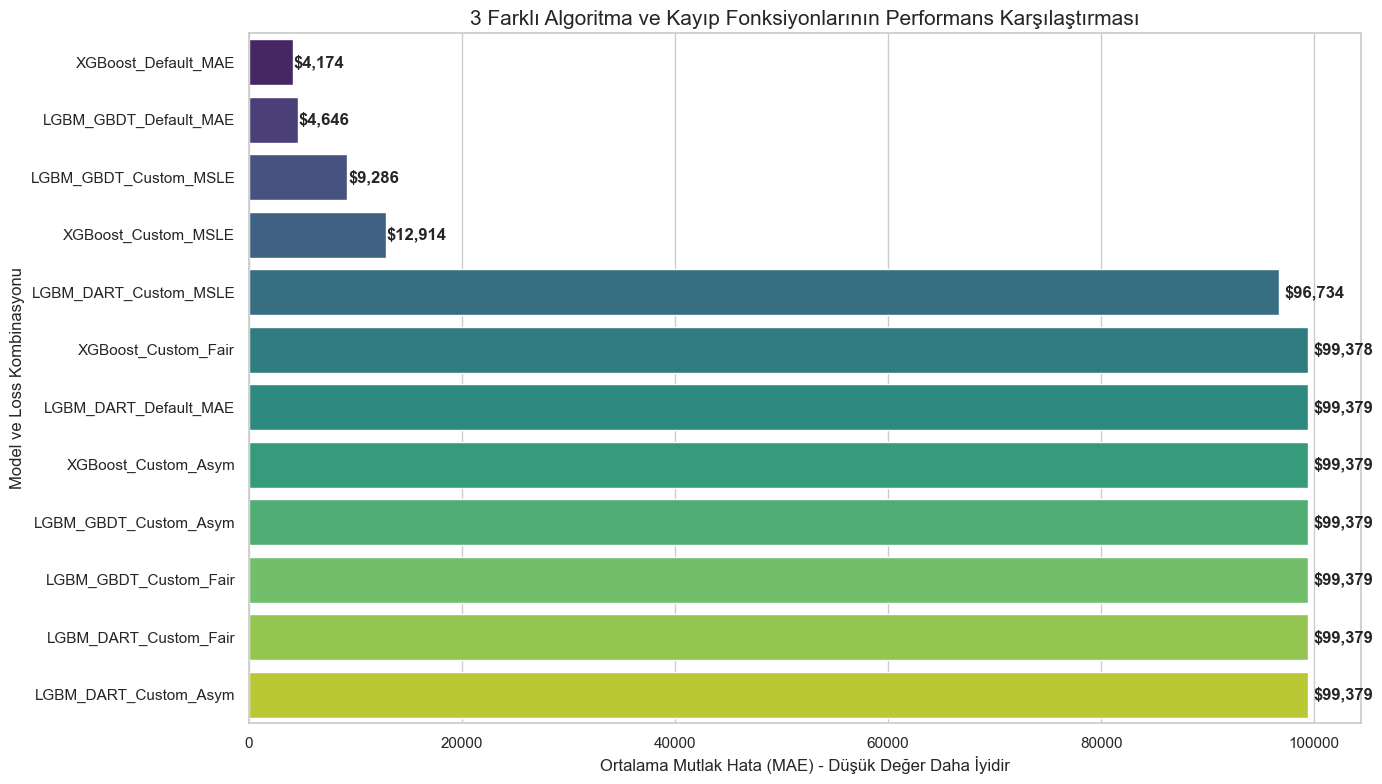

In [ ]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, r2_score, make_scorer
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor 



cat_cols = ['Job Title', 'Location', 'Headquarters', 'Type of ownership', 'Sector']
num_cols = df_model.drop('average_salary', axis=1).select_dtypes(include=['int64', 'float64']).columns.tolist()

# Algoritmaların kategorik değişkenleri tanıması için tip dönüşümü
for col in cat_cols:
    df_model[col] = df_model[col].astype('category')

X = df_model.drop('average_salary', axis=1)
y = df_model['average_salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


def augment_rare_categories(X_subset, y_subset, cat_col, num_columns, min_samples=20, noise_std=0.02):
    X_aug = X_subset.copy()
    y_aug = y_subset.copy()
    
    value_counts = X_aug[cat_col].value_counts()
    rare_categories = value_counts[value_counts < min_samples].index
    
    augmented_X_list = []
    augmented_y_list = []
    
    for category in rare_categories:
        cat_mask = X_aug[cat_col] == category
        X_cat = X_aug[cat_mask]
        y_cat = y_aug[cat_mask]
        
        current_count = len(X_cat)
        if current_count == 0: continue
            
        samples_to_add = min_samples - current_count
        
        if samples_to_add > 0:
            sample_indices = np.random.choice(X_cat.index, size=samples_to_add, replace=True)
            X_new = X_aug.loc[sample_indices].copy()
            y_new = y_aug.loc[sample_indices].copy()
            
            for col in num_columns:
                if col in X_new.columns:
                    col_std = X_new[col].std()
                    noise_scale = noise_std * col_std if pd.notna(col_std) and col_std > 0 else 0.01
                    noise = np.random.normal(0, noise_scale, size=len(X_new))
                    X_new[col] = np.round(X_new[col] + noise, 2)
            
            augmented_X_list.append(X_new)
            augmented_y_list.append(y_new)
    
    if augmented_X_list:
        X_aug = pd.concat([X_aug] + augmented_X_list, ignore_index=True)
        y_aug = pd.concat([y_aug] + augmented_y_list, ignore_index=True)
        
    for col in cat_cols:
        if col in X_aug.columns:
            X_aug[col] = X_aug[col].astype('category')
            
    return X_aug, y_aug

X_train, y_train = augment_rare_categories(
    X_subset=X_train, y_subset=y_train, cat_col='Job Title', 
    num_columns=num_cols, min_samples=20, noise_std=0.02
)


# 1. Custom Fair Loss (Aykırı Değerlere Karşı Dirençli)
def custom_fair_obj(y_true, y_pred):
    c = 0.1 
    x = y_pred - y_true
    denominator = np.abs(x) + c
    grad = (c * x) / denominator
    hess = (c * c) / (denominator**2)
    return grad, hess

# 2. Custom MSLE (Oransal Hata Dağılımı)
def custom_msle_obj(y_true, y_pred):
    y_pred = np.clip(y_pred, a_min=0, a_max=None)
    y_true = np.clip(y_true, a_min=0, a_max=None)
    grad = (np.log1p(y_pred) - np.log1p(y_true)) / (y_pred + 1)
    hess = (1 - np.log1p(y_pred) + np.log1p(y_true)) / ((y_pred + 1)**2)
    return grad, hess

# 3. Custom Asymmetric Loss (Eksik Tahmini 3 Kat Fazla Cezalandırır)
def custom_asymmetric_obj(y_true, y_pred):
    residual = y_pred - y_true
    grad = np.where(residual < 0, -3.0 * residual, 1.0 * residual)
    hess = np.where(residual < 0, 3.0, 1.0)
    return grad, hess


models_to_train = [
    # ALGORİTMA 1: XGBoost
    ('XGBoost_Default_MAE', XGBRegressor(objective='reg:absoluteerror', enable_categorical=True, tree_method='hist', random_state=42)),
    ('XGBoost_Custom_Fair', XGBRegressor(objective=custom_fair_obj, enable_categorical=True, tree_method='hist', random_state=42)),
    ('XGBoost_Custom_MSLE', XGBRegressor(objective=custom_msle_obj, enable_categorical=True, tree_method='hist', random_state=42)),
    ('XGBoost_Custom_Asym', XGBRegressor(objective=custom_asymmetric_obj, enable_categorical=True, tree_method='hist', random_state=42)),
    
    # ALGORİTMA 2: LightGBM (GBDT)
    ('LGBM_GBDT_Default_MAE', LGBMRegressor(objective='mae', random_state=42, verbose=-1)),
    ('LGBM_GBDT_Custom_Fair', LGBMRegressor(objective=custom_fair_obj, random_state=42, verbose=-1)),
    ('LGBM_GBDT_Custom_MSLE', LGBMRegressor(objective=custom_msle_obj, random_state=42, verbose=-1)),
    ('LGBM_GBDT_Custom_Asym', LGBMRegressor(objective=custom_asymmetric_obj, random_state=42, verbose=-1)),
    
    # ALGORİTMA 3: LightGBM (DART - Dropout Mimarisi)
    ('LGBM_DART_Default_MAE', LGBMRegressor(boosting_type='dart', objective='mae', random_state=42, verbose=-1)),
    ('LGBM_DART_Custom_Fair', LGBMRegressor(boosting_type='dart', objective=custom_fair_obj, random_state=42, verbose=-1)),
    ('LGBM_DART_Custom_MSLE', LGBMRegressor(boosting_type='dart', objective=custom_msle_obj, random_state=42, verbose=-1)),
    ('LGBM_DART_Custom_Asym', LGBMRegressor(boosting_type='dart', objective=custom_asymmetric_obj, random_state=42, verbose=-1))
]

# GridSearch Dar Uzayı (Süreyi çok uzatmamak için)
param_grid = {
    'regressor__n_estimators': [100],
    'regressor__max_depth': [5]
}

scoring = {'MAE': make_scorer(mean_absolute_error, greater_is_better=False)}
cv = KFold(n_splits=3, shuffle=True, random_state=42)


results_list = []

print(f"Toplam 12 Model Eğitimi Başlıyor...\n{'-'*50}")

for i, (model_name, base_model) in enumerate(models_to_train, 1):
    print(f"[{i}/12] Eğitiliyor: {model_name}... (Lütfen bekleyin)")
    
    ttr = TransformedTargetRegressor(regressor=base_model, func=np.log1p, inverse_func=np.expm1)
    
    
    gs = GridSearchCV(estimator=ttr, param_grid=param_grid, scoring=scoring, refit='MAE', cv=cv, n_jobs=2, verbose=0)
    
    
    gs.fit(X_train, y_train)
    
    best_mae = -gs.cv_results_['mean_test_MAE'][gs.best_index_]
    print(f"        Tamamlandı! Skor (MAE): {best_mae:.2f}")
    
    results_list.append({
        'Model_Name': model_name,
        'Algorithm': model_name.split('_')[0] + ('_DART' if 'DART' in model_name else ''),
        'Loss_Type': model_name.split('_')[-1],
        'Best_MAE': best_mae
    })

results_df = pd.DataFrame(results_list).sort_values(by='Best_MAE')
display(results_df)

# Görselleştirme
plt.figure(figsize=(14, 8))
sns.barplot(x='Best_MAE', y='Model_Name', data=results_df, palette='viridis')
plt.title('3 Farklı Algoritma ve Kayıp Fonksiyonlarının Performans Karşılaştırması', fontsize=15)
plt.xlabel('Ortalama Mutlak Hata (MAE) - Düşük Değer Daha İyidir', fontsize=12)
plt.ylabel('Model ve Loss Kombinasyonu', fontsize=12)

for index, value in enumerate(results_df['Best_MAE']):
    plt.text(value + (value*0.005), index, f"${value:,.0f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

--- ŞAMPİYON MODEL (XGBoost_Default_MAE) TEST SETİ PERFORMANSI ---
Test MAE (Ortalama Mutlak Hata): $12,460 (Aday başına ortalama sapma)
Test RMSE (Kök Ortalama Kare Hata): $22,476 (Büyük hatalara karşı hassas sapma)
Test R2 Skoru (Açıklanabilirlik Oranı): 0.655


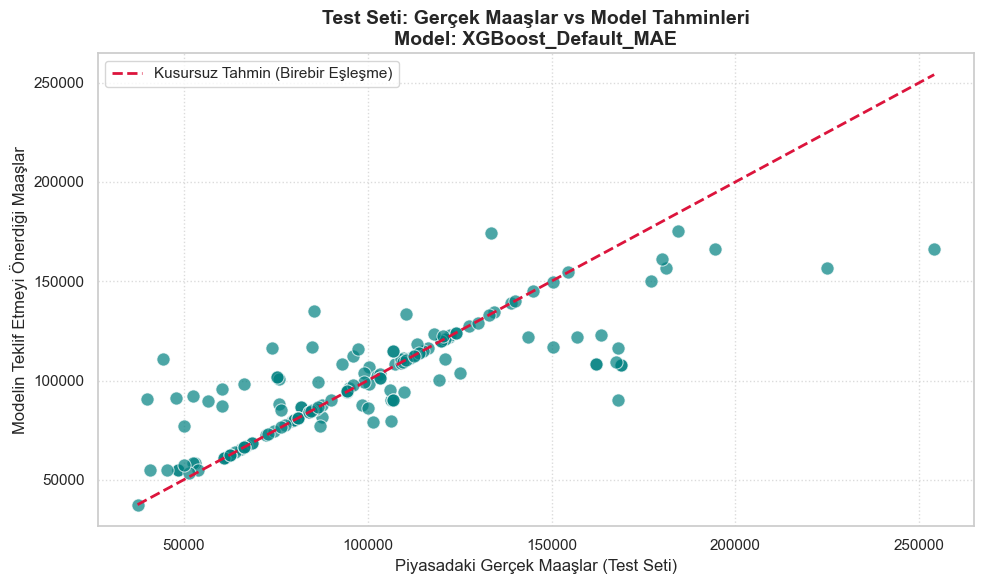

In [ ]:
# model ile el değmemiş Test Seti (X_test) üzerinde tahmin yapıyoruz
y_pred_test = ttr_best.predict(X_test)

# Test metriklerini hesaplıyoruz
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_r2 = r2_score(y_test, y_pred_test)

print(f"--- ŞAMPİYON MODEL ({best_model_name}) TEST SETİ PERFORMANSI ---")
print(f"Test MAE (Ortalama Mutlak Hata): ${test_mae:,.0f} (Aday başına ortalama sapma)")
print(f"Test RMSE (Kök Ortalama Kare Hata): ${test_rmse:,.0f} (Büyük hatalara karşı hassas sapma)")
print(f"Test R2 Skoru (Açıklanabilirlik Oranı): {test_r2:.3f}")

# İK Bütçe Sapması Görselleştirmesi (Gerçek vs Tahmin)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.7, color='teal', edgecolor='w', s=90)

# Mükemmel tahmin çizgisi (Gerçek = Tahmin)
max_val = max(y_test.max(), y_pred_test.max())
min_val = min(y_test.min(), y_pred_test.min())
plt.plot([min_val, max_val], [min_val, max_val], color='crimson', linestyle='--', linewidth=2, label='Kusursuz Tahmin (Birebir Eşleşme)')

plt.title(f'Test Seti: Gerçek Maaşlar vs Model Tahminleri\nModel: {best_model_name}', fontsize=14, fontweight='bold')
plt.xlabel('Piyasadaki Gerçek Maaşlar (Test Seti)', fontsize=12)
plt.ylabel('Modelin Teklif Etmeyi Önerdiği Maaşlar', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Test seti üzerinde değişken önemleri (Permutation Importance) hesaplanıyor...
Mantık: Bir değişken rastgele karıştırıldığında MAE hatası ne kadar artıyorsa, o değişken o kadar önemlidir.


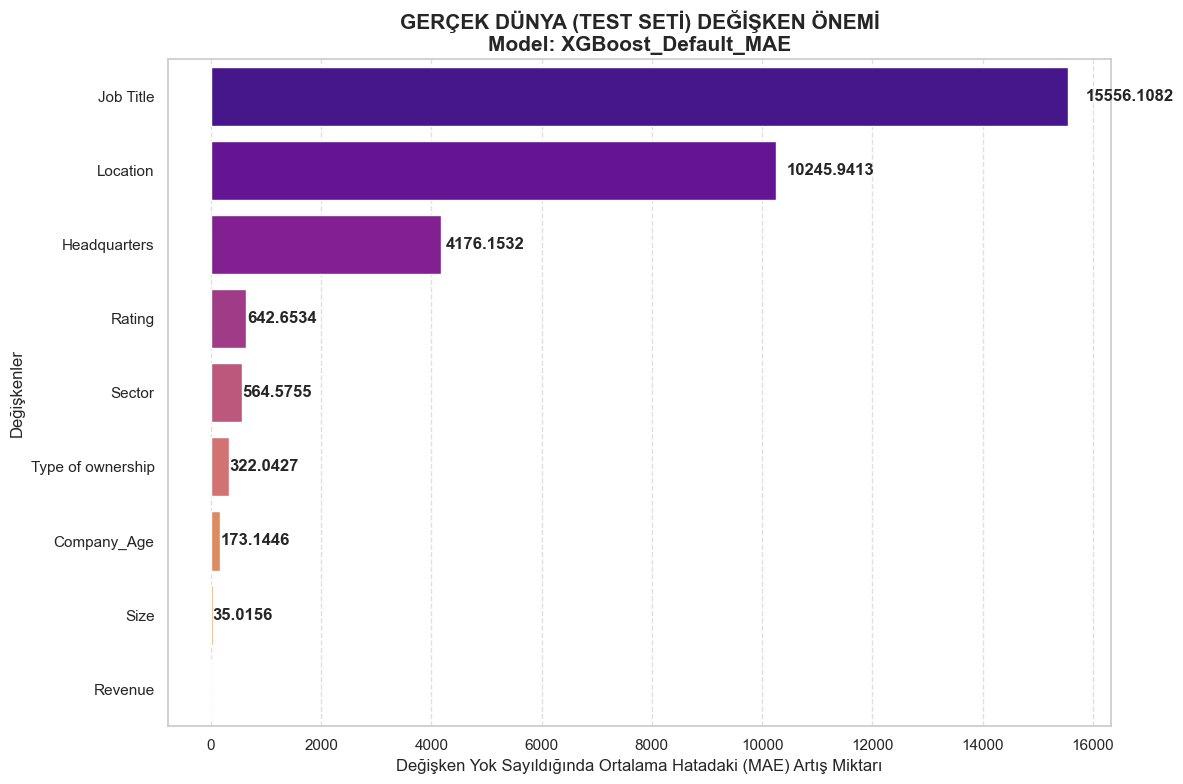

In [ ]:
from sklearn.inspection import permutation_importance

print("Test seti üzerinde değişken önemleri (Permutation Importance) hesaplanıyor...")
print("Mantık: Bir değişken rastgele karıştırıldığında MAE hatası ne kadar artıyorsa, o değişken o kadar önemlidir.")

# Test seti üzerinde her değişkeni 5 kez (n_repeats) karıştırarak MAE üzerindeki etkisini ölçüyoruz
perm_importance = permutation_importance(
    estimator=ttr_best, 
    X=X_test, 
    y=y_test, 
    scoring='neg_mean_absolute_error', # MAE metriğine göre etkiyi ölçecek
    n_repeats=5, 
    random_state=42, 
    n_jobs=2
)

# Çıkan sonuçları bir tabloya (DataFrame) dönüştürüyoruz
feature_names = X_test.columns
perm_imp_df = pd.DataFrame({
    'Feature': feature_names,
    # Hata değerindeki artışı (negatif kaybı) pozitife çeviriyoruz ki grafik düzgün çıksın
    'Importance_Impact': perm_importance.importances_mean, 
    'Std_Dev': perm_importance.importances_std
}).sort_values(by='Importance_Impact', ascending=False)

# Sadece modeli gerçekten etkileyen (önemi 0'dan büyük) en kritik ilk 15 değişken
top_test_features = perm_imp_df.head(15)

# Görselleştirme
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance_Impact', y='Feature', data=top_test_features, palette='plasma')

plt.title(f'GERÇEK DÜNYA (TEST SETİ) DEĞİŞKEN ÖNEMİ\nModel: {best_model_name}', fontsize=15, fontweight='bold')
plt.xlabel('Değişken Yok Sayıldığında Ortalama Hatadaki (MAE) Artış Miktarı', fontsize=12)
plt.ylabel('Değişkenler', fontsize=12)

for index, value in enumerate(top_test_features['Importance_Impact']):
    if value > 0:
        plt.text(value + (value*0.02), index, f"{value:.4f}", va='center', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Sadece tahmin için gereken özellikleri seçiyoruz (average_salary hariç)
X_inference = df_tahmin_edilecek.drop('average_salary', axis=1)

# modellerin  çalışabilmesi için 
# kategorik değişkenleri 'category' tipine dönüştürmeliyiz.
cat_cols = ['Job Title', 'Location', 'Headquarters', 'Type of ownership', 'Sector']
for col in cat_cols:
    if col in X_inference.columns:
        X_inference[col] = X_inference[col].astype('category')

print(f"Şampiyon Model ({best_model_name}) ile NaN değerler için maaş tahminleri oluşturuluyor...")

# Daha önce belirlediğimiz ve tüm eğitim verisiyle eğittiğimiz 'ttr_best' modelini kullanıyoruz
nan_predictions = ttr_best.predict(X_inference)

#  Tahminleri 'average_salary' sütununa geri basıyoruz
df_tahmin_edilecek['average_salary'] = nan_predictions
df_tahmin_edilecek['average_salary'] = df_tahmin_edilecek['average_salary'].round(2)

print("İşlem tamam! Eksik maaş verileri, piyasa dinamiklerini en iyi anlayan model ile dolduruldu.")

# İlk birkaç satıra bakarak İK bütçe tahminlerini görelim
display(df_tahmin_edilecek[['Job Title', 'Location', 'average_salary']].head(10))

# Orijinal (gerçek) maaş verisi ile yeni (tahmin edilmiş) veriyi birleştiriyoruz
df_final_dataset = pd.concat([df_model, df_tahmin_edilecek], axis=0).reset_index(drop=True)

print(f"Toplam birleştirilmiş veri boyutu: {df_final_dataset.shape[0]} satır.")

Şampiyon Model (XGBoost_Default_MAE) ile NaN değerler için maaş tahminleri oluşturuluyor...
İşlem tamam! Eksik maaş verileri, piyasa dinamiklerini en iyi anlayan model ile dolduruldu.


,Job Title,Location,average_salary
24,Data Scientist,Oregon,114934.601562
42,Data Scientist,"Chicago, IL",103774.078125
47,Data Science Analyst,"Chandler, AZ",97823.046875
53,Data Engineer,"Kingdom, IL",81619.242188
64,Business Intelligence Analyst,"Lincoln, RI",93020.429688
69,Data Scientist,"San Francisco, CA",105024.789062
71,Data Scientist,"Chantilly, VA",92884.796875
74,Data Scientist,New Jersey,83211.523438
98,Machine Learning Engineer,"Mountain View, CA",108164.546875
100,Data Engineer Intern,"San Francisco, CA",106876.460938


Toplam birleştirilmiş veri boyutu: 945 satır.


Tahmin tablosuna formatlı aralıklar eklendi:


,Job Title,Location,salary_prediction_final
24,Data Scientist,Oregon,"$114,935 (Range: $102,475 - $127,394)"
42,Data Scientist,"Chicago, IL","$103,774 (Range: $91,314 - $116,234)"
47,Data Science Analyst,"Chandler, AZ","$97,823 (Range: $85,363 - $110,283)"
53,Data Engineer,"Kingdom, IL","$81,619 (Range: $69,159 - $94,079)"
64,Business Intelligence Analyst,"Lincoln, RI","$93,020 (Range: $80,561 - $105,480)"


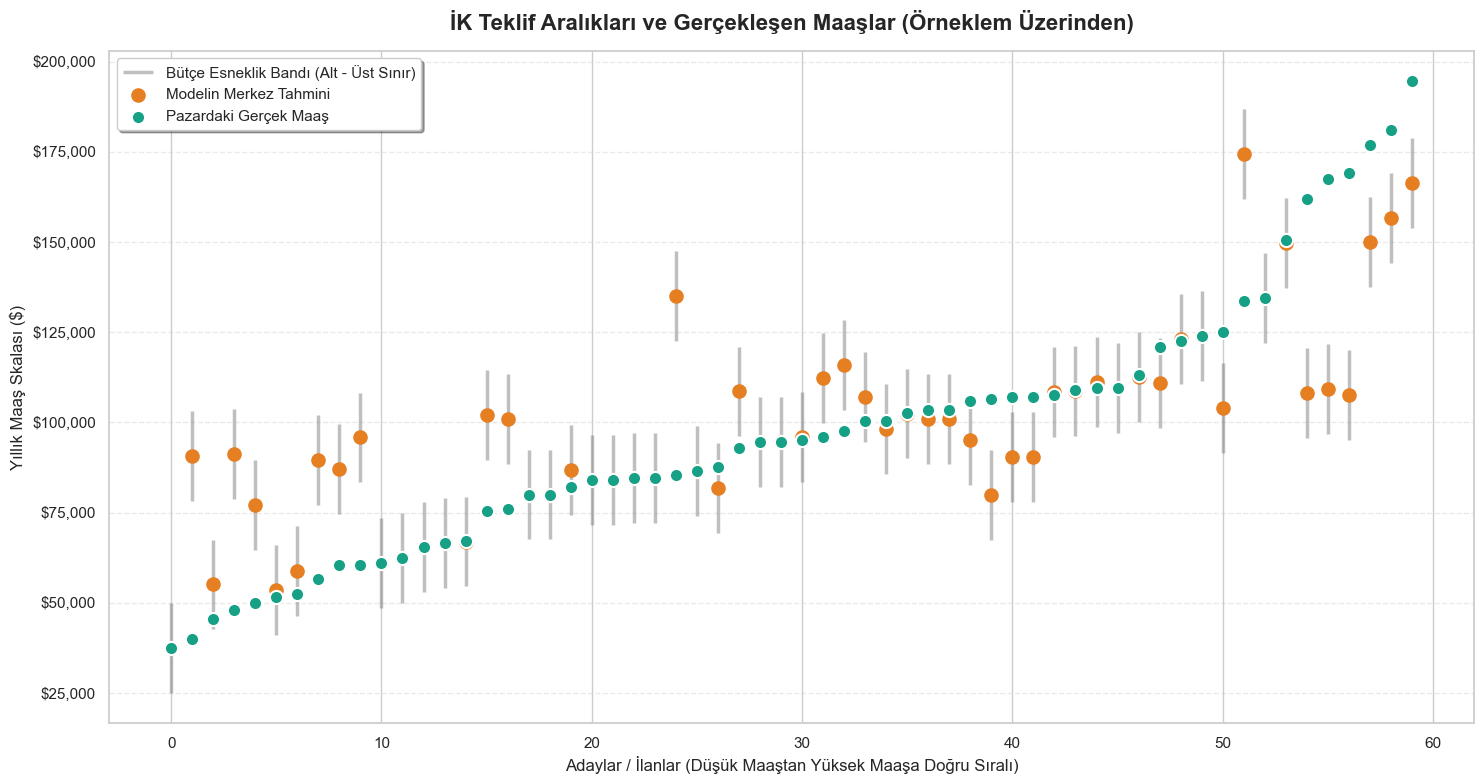

In [ ]:
# Test MAE'yi hata payı olarak kullanarak alt ve üst sınırları belirliyoruz
hata_payi = test_mae

df_tahmin_edilecek['lower_bound'] = df_tahmin_edilecek['average_salary'] - hata_payi
df_tahmin_edilecek['upper_bound'] = df_tahmin_edilecek['average_salary'] + hata_payi

# Maaşları binlik ayraçlı ve $ işaretli şık bir metne dönüştüren fonksiyon
def format_salary_range(row):
    avg = f"${row['average_salary']:,.0f}"
    low = f"${row['lower_bound']:,.0f}"
    high = f"${row['upper_bound']:,.0f}"
    return f"{avg} (Range: {low} - {high})"

# Yeni tek değişkenli sütunumuzu oluşturuyoruz
df_tahmin_edilecek['salary_prediction_final'] = df_tahmin_edilecek.apply(format_salary_range, axis=1)

print("Tahmin tablosuna formatlı aralıklar eklendi:")
display(df_tahmin_edilecek[['Job Title', 'Location', 'salary_prediction_final']].head())



plot_df = pd.DataFrame({
    'Gercek_Maas': y_test.values,
    'Tahmin_Edilen_Maas': y_pred_test,
    'Alt_Sinir': y_pred_test - hata_payi,
    'Ust_Sinir': y_pred_test + hata_payi
})

# Görselin çorba olmaması ve trendin net okunması için test setinden 
# rastgele 60 adayı seçip düşük maaştan yüksek maaşa doğru sıralıyoruz
sample_df = plot_df.sample(n=60, random_state=42).sort_values(by='Gercek_Maas').reset_index(drop=True)

plt.figure(figsize=(15, 8))

# Bütçe Esneklik Bandı (Alt ve Üst sınırları birleştiren ince dikey çizgiler)
plt.vlines(x=sample_df.index, ymin=sample_df['Alt_Sinir'], ymax=sample_df['Ust_Sinir'], 
           color='gray', alpha=0.5, linewidth=2.5, label='Bütçe Esneklik Bandı (Alt - Üst Sınır)')

# Modelin Merkez Tahmini (Turuncu Noktalar)
plt.scatter(sample_df.index, sample_df['Tahmin_Edilen_Maas'], 
            color='#E67E22', s=90, zorder=3, label='Modelin Merkez Tahmini')

# Pazardaki Gerçek Maaş (Yeşil, içi dolu ve kenarlıklı noktalar)
plt.scatter(sample_df.index, sample_df['Gercek_Maas'], 
            color='#16A085', s=90, edgecolor='white', linewidth=1.5, zorder=4, label='Pazardaki Gerçek Maaş')

# Grafik Ayarları
plt.title('İK Teklif Aralıkları ve Gerçekleşen Maaşlar (Örneklem Üzerinden)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Adaylar / İlanlar (Düşük Maaştan Yüksek Maaşa Doğru Sıralı)', fontsize=12)
plt.ylabel('Yıllık Maaş Skalası ($)', fontsize=12)

# Y eksenini dolar ve binlik ayraç formatına çevirme
current_values = plt.gca().get_yticks()
plt.gca().set_yticklabels(['${:,.0f}'.format(x) for x in current_values])

plt.legend(loc='upper left', fontsize=11, frameon=True, shadow=True)
plt.grid(axis='y', linestyle='--', alpha=0.4) # Sadece yatay ızgara çizgileri
plt.tight_layout()
plt.show()